# Cuff-less Blood Pressure Data Preprocessing

This notebook preprocesses the UCI Cuff-less Blood Pressure dataset for blood pressure estimation using PPG signals.

The preprocessing steps include loading the MATLAB v7.3 data, separating PPG and ABP signals, checking for invalid values, creating 5-second windows, extracting systolic and diastolic blood pressure labels, checking for potential outliers, and normalizing the PPG signals.

In [4]:
import numpy as np
from scipy.signal import find_peaks
import matplotlib.pyplot as plt
from pathlib import Path
import mat73

## Load the Dataset

The dataset is stored as a MATLAB v7.3 file and is loaded using `mat73`. Part 1 of the dataset contains 3,000 physiological signal records.

## Preprocess All Records

Each record contains PPG and ABP signals sampled at 125 Hz. The signals are divided into 5-second windows, giving 625 samples per window.

For each window, peaks and valleys in the ABP signal are used to estimate systolic and diastolic blood pressure. The corresponding PPG window is normalized using z-score normalization. Windows with invalid data, missing peaks or valleys, or flat PPG signals are skipped.

In [5]:

#returns all_ppg_windows, all_abp_windows, all_systolic_labels, all_diastolic_labels
def check_part(part_number, wantResult = True, removePrint = False):
    # Keep moving upward until we find the real dataset, should be in the data folder but if for some reason we are somewhere else should still be able to find it
    ROOT = Path.cwd()

    while ROOT != ROOT.parent and not (ROOT / "data" / "Part_1.mat").exists():
        ROOT = ROOT.parent

    DATA_DIR = ROOT / "data"
    
    # Builds the file name depending on which part we are checking
    file_path = DATA_DIR / f"Part_{part_number}.mat"
    key = f"Part_{part_number}"

    if not removePrint:
        print("\n" + "=" * 60)
        print(f"CHECKING PART {part_number}")
        print("=" * 60)

    if not file_path.exists():
        print(f"Part_{part_number}.mat was NOT found.")
        return

    if not removePrint:
        print(f"Loading Part_{part_number}...")

    data = mat73.loadmat(file_path)
    records = data[key]

    if not removePrint:
        print("Loaded!")
        print("Number of records:", len(records))

    all_ppg_windows = []
    all_abp_windows = []
    all_systolic_labels = []
    all_diastolic_labels = []

    window_size = 625

    invalid_records = 0
    flat_ppg_windows = 0
    no_peak_windows = 0

    for i in range(len(records)):

        record = np.asarray(records[i])

        ppg = record[0]
        abp = record[1]

        # Skip records with invalid values
        if not np.all(np.isfinite(ppg)) or not np.all(np.isfinite(abp)):
            invalid_records += 1
            continue

        # Create 5-second windows 
        #Note, changed this for loop to help with speed hopefully it works, if not can change back to the original for loop
        num_windows = len(ppg) // window_size
        ppg_windows = ppg[:num_windows * window_size].reshape(num_windows, window_size)
        abp_windows = abp[:num_windows * window_size].reshape(num_windows, window_size)

        # Calculate mean/std for every PPG window at once (hopefully this is faster)
        ppg_means = np.mean(ppg_windows, axis=1)
        ppg_stds = np.std(ppg_windows, axis=1)

        for j in range(num_windows):

            if ppg_stds[j] == 0:
                flat_ppg_windows += 1
                continue

            ppg_window = ppg_windows[j]
            abp_window = abp_windows[j]

            peaks, _ = find_peaks(abp_window, distance=50)
            valleys, _ = find_peaks(-abp_window, distance=50)

            if len(peaks) == 0 or len(valleys) == 0:
                no_peak_windows += 1
                continue

            systolic = np.median(abp_window[peaks])
            diastolic = np.median(abp_window[valleys])

            normalized_ppg = (
                ppg_window - ppg_means[j]
            ) / ppg_stds[j]

            all_ppg_windows.append(normalized_ppg)
            all_abp_windows.append(abp_window)
            all_systolic_labels.append(systolic)
            all_diastolic_labels.append(diastolic)
            

            
    

    #Used for analysis later
    all_ppg_windows = np.array(all_ppg_windows)
    all_abp_windows = np.array(all_abp_windows)
    all_systolic_labels = np.array(all_systolic_labels)
    all_diastolic_labels = np.array(all_diastolic_labels)


    if(wantResult or not removePrint):
        #Results:
        print("Records processed:", len(records))
        print("Invalid records skipped:", invalid_records)
        print("Flat PPG windows skipped:", flat_ppg_windows)
        print("Windows without peaks/valleys:", no_peak_windows)

        print("\nTotal valid examples:", len(all_ppg_windows))

        print("PPG dataset shape:", all_ppg_windows.shape)
        print("ABP dataset shape:", all_abp_windows.shape)
        print("Systolic labels shape:", all_systolic_labels.shape)
        print("Diastolic labels shape:", all_diastolic_labels.shape)

    #Returns the windows for later analysis
    return (all_ppg_windows, all_abp_windows, all_systolic_labels, all_diastolic_labels)
    


In [6]:
#Storing them so the preprocessing doesn't have to be done again and again, can just load the results from this variable
#This was the best way to make it faster
part1 = check_part(1)
part2 = check_part(2)
part3 = check_part(3)
part4 = check_part(4)


CHECKING PART 1
Loading Part_1...
Loaded!
Number of records: 3000
Records processed: 3000
Invalid records skipped: 0
Flat PPG windows skipped: 0
Windows without peaks/valleys: 1

Total valid examples: 131162
PPG dataset shape: (131162, 625)
ABP dataset shape: (131162, 625)
Systolic labels shape: (131162,)
Diastolic labels shape: (131162,)

CHECKING PART 2
Loading Part_2...
Loaded!
Number of records: 3000
Records processed: 3000
Invalid records skipped: 0
Flat PPG windows skipped: 0
Windows without peaks/valleys: 1

Total valid examples: 151304
PPG dataset shape: (151304, 625)
ABP dataset shape: (151304, 625)
Systolic labels shape: (151304,)
Diastolic labels shape: (151304,)

CHECKING PART 3
Loading Part_3...
Loaded!
Number of records: 3000
Records processed: 3000
Invalid records skipped: 0
Flat PPG windows skipped: 0
Windows without peaks/valleys: 1

Total valid examples: 112449
PPG dataset shape: (112449, 625)
ABP dataset shape: (112449, 625)
Systolic labels shape: (112449,)
Diastoli

## Blood Pressure Range and Outlier Check

The systolic and diastolic labels are checked to understand their overall ranges and identify potentially unusual values. Extreme values are flagged for investigation rather than automatically removed because they may represent real physiological measurements.

In [7]:
#Ranges
def check_ranges(partNum, part):
      print("\n" + "=" * 60)
      print(f"Part {partNum} Ranges")
      print("=" * 60)

      all_ppg_windows, all_abp_windows, all_systolic_labels, all_diastolic_labels = part #The _ ignores the new recording ID array because this function doesn't need it
      print("Lowest systolic:", np.min(all_systolic_labels))
      print("Highest systolic:", np.max(all_systolic_labels))
      print("Lowest diastolic:", np.min(all_diastolic_labels))
      print("Highest diastolic:", np.max(all_diastolic_labels))
      print("\nExtreme BP labels:")
      print("Systolic below 70:",
            np.sum(all_systolic_labels < 70))
      print("Systolic above 180:",
            np.sum(all_systolic_labels > 180))
      print("Diastolic below 40:",
            np.sum(all_diastolic_labels < 40))
      print("Diastolic above 120:",
            np.sum(all_diastolic_labels > 120))



In [8]:
check_ranges(1, part1)
check_ranges(2, part2)
check_ranges(3, part3)
check_ranges(4, part4)


Part 1 Ranges
Lowest systolic: 56.00459524884093
Highest systolic: 199.28375075464066
Lowest diastolic: 50.0
Highest diastolic: 186.78003719970616

Extreme BP labels:
Systolic below 70: 11
Systolic above 180: 2726
Diastolic below 40: 0
Diastolic above 120: 393

Part 2 Ranges
Lowest systolic: 60.2592216220071
Highest systolic: 199.63542796185476
Lowest diastolic: 50.0
Highest diastolic: 187.7445078864427

Extreme BP labels:
Systolic below 70: 10
Systolic above 180: 2533
Diastolic below 40: 0
Diastolic above 120: 433

Part 3 Ranges
Lowest systolic: 61.055130340492255
Highest systolic: 199.28414010847308
Lowest diastolic: 50.0
Highest diastolic: 181.64127752606808

Extreme BP labels:
Systolic below 70: 25
Systolic above 180: 1757
Diastolic below 40: 0
Diastolic above 120: 147

Part 4 Ranges
Lowest systolic: 60.82142165672859
Highest systolic: 198.42787682301713
Lowest diastolic: 50.06522168528141
Highest diastolic: 177.59716313442388

Extreme BP labels:
Systolic below 70: 55
Systolic abo

### Blood Pressure Findings 

Across the processed Part 1 data, systolic labels ranged from approximately 59.52 to 197.99 mmHg and diastolic labels ranged from 50.00 to 188.12 mmHg.

There were 9 systolic labels below 70 mmHg, 2,117 above 180 mmHg, and 382 diastolic labels above 120 mmHg. These values were flagged as potentially unusual but were not automatically removed because additional investigation of the ABP waveforms is needed to determine whether they represent real measurements or noisy data.

## Blood Pressure Distribution

The distributions of the systolic and diastolic blood pressure labels are visualized using histograms. This helps show where most blood pressure values are concentrated and whether extreme values appear frequently in the dataset.

In [9]:
def plot_bp_distribution(partNum, part):
    all_ppg_windows, all_abp_windows, all_systolic_labels, all_diastolic_labels = part
    plt.figure(figsize=(8, 5))
    print("\n" + "=" * 60)
    print(f"Part {partNum} Distributions")
    print("=" * 60)
    # Calculate mean and standard deviation
    sbp_mean = np.mean(all_systolic_labels)
    sbp_std = np.std(all_systolic_labels)

    dbp_mean = np.mean(all_diastolic_labels)
    dbp_std = np.std(all_diastolic_labels)

    # Histograms
    plt.hist(all_systolic_labels, bins=50, alpha=0.7, label="Systolic")
    plt.hist(all_diastolic_labels, bins=50, alpha=0.7, label="Diastolic")

    # Mean lines
    plt.axvline(sbp_mean, linestyle="--",
                label=f"Systolic Mean: {sbp_mean:.1f}")

    plt.axvline(dbp_mean, linestyle="--",
                label=f"Diastolic Mean: {dbp_mean:.1f}")

    plt.xlabel("Blood Pressure (mmHg)")
    plt.ylabel("Number of Windows")
    plt.title("Blood Pressure Distribution")
    plt.legend()

    plt.show()

    print("Systolic mean:", sbp_mean)
    print("Systolic standard deviation:", sbp_std)

    print("Diastolic mean:", dbp_mean)
    print("Diastolic standard deviation:", dbp_std)

    print("First window mean:",
      np.mean(all_ppg_windows[0]))

    print("First window standard deviation:",
      np.std(all_ppg_windows[0]))


Part 1 Distributions


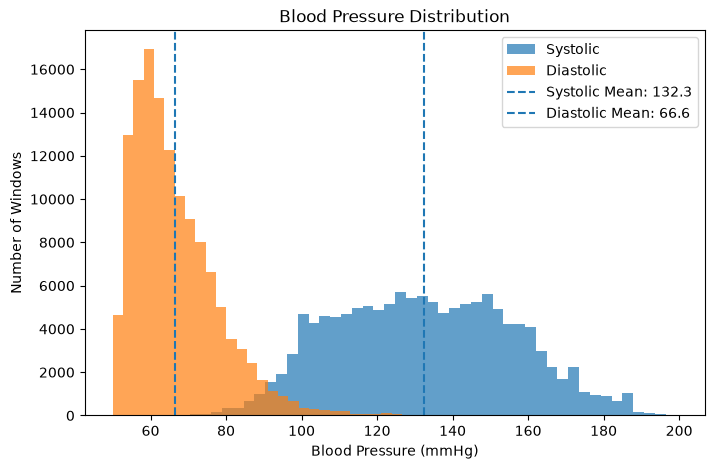

Systolic mean: 132.3368326425103
Systolic standard deviation: 23.423556994839277
Diastolic mean: 66.56742444252036
Diastolic standard deviation: 11.527092928497403
First window mean: 7.105427357601002e-17
First window standard deviation: 1.0

Part 2 Distributions


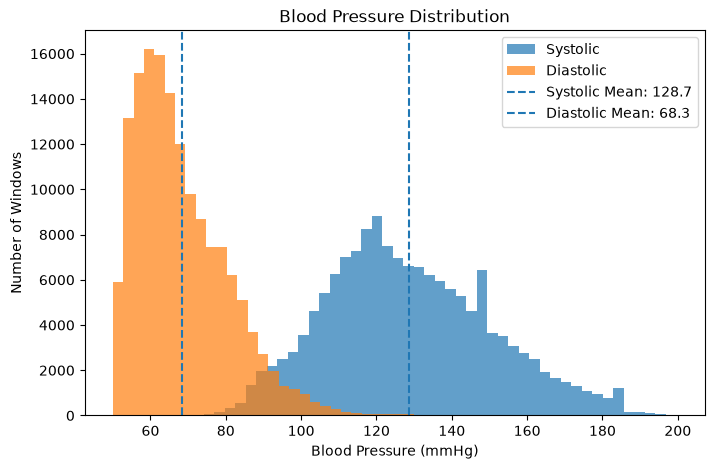

Systolic mean: 128.70183409570046
Systolic standard deviation: 21.977390330211083
Diastolic mean: 68.32880963963689
Diastolic standard deviation: 12.517192900351086
First window mean: 1.3926637620897963e-16
First window standard deviation: 1.0000000000000002

Part 3 Distributions


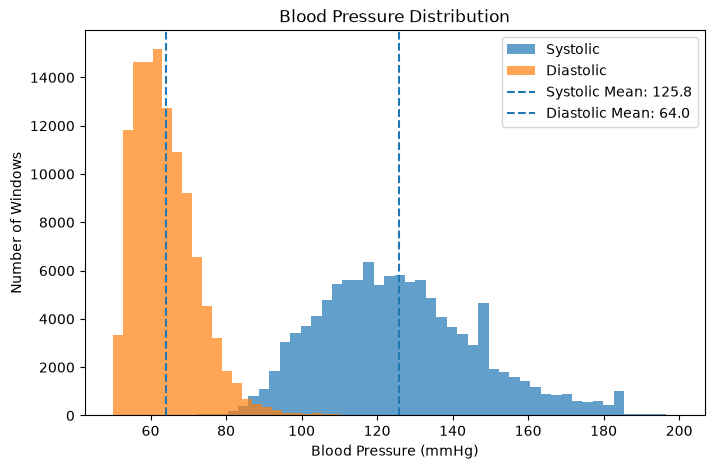

Systolic mean: 125.7803109564655
Systolic standard deviation: 21.070740323554023
Diastolic mean: 63.99844352883162
Diastolic standard deviation: 8.7727925567927
First window mean: -2.1600499167107046e-16
First window standard deviation: 1.0

Part 4 Distributions


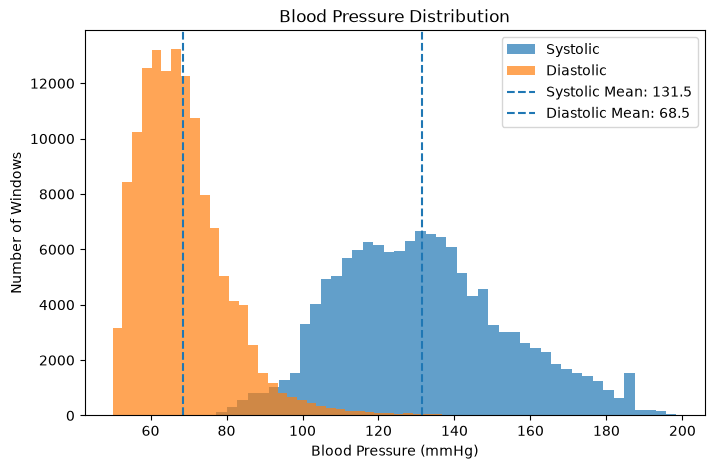

Systolic mean: 131.520307198083
Systolic standard deviation: 22.29312476113033
Diastolic mean: 68.53425963422161
Diastolic standard deviation: 11.893272787872583
First window mean: 0.0
First window standard deviation: 0.9999999999999998


In [10]:
plot_bp_distribution(1, part1)
plot_bp_distribution(2, part2)
plot_bp_distribution(3, part3)
plot_bp_distribution(4, part4)

## Signal Quality Investigation

PPG and ABP waveforms are visualized to examine the quality of the signals and investigate potentially unusual blood pressure labels. This helps determine whether extreme labels represent valid physiological signals or noisy data.

In [11]:
def qualityInvesting(partNum, part):
    all_ppg_windows, all_abp_windows, all_systolic_labels, all_diastolic_labels = part
    normal_indices = np.where(
        (all_systolic_labels >= 100) &
        (all_systolic_labels <= 140) &
        (all_diastolic_labels >= 60) &
        (all_diastolic_labels <= 90)
    )[0]

    print("\n" + "=" * 60)
    print(f"Part {partNum} Quality Investing")
    print("=" * 60)
    normal_index = normal_indices[0]

    print("Window index:", normal_index)
    print("Systolic:", all_systolic_labels[normal_index])
    print("Diastolic:", all_diastolic_labels[normal_index])

    plt.figure(figsize=(10, 4))
    plt.plot(all_ppg_windows[normal_index])

    plt.title("Normalized PPG - Typical Window")
    plt.xlabel("Sample")
    plt.ylabel("Normalized PPG")
    plt.show()

    plt.figure(figsize=(10, 4))
    plt.plot(all_abp_windows[normal_index])

    plt.title("ABP - Typical Window")
    plt.xlabel("Sample")
    plt.ylabel("Blood Pressure (mmHg)")
    plt.show()


Part 1 Quality Investing
Window index: 0
Systolic: 121.84161810748634
Diastolic: 67.18506542667768


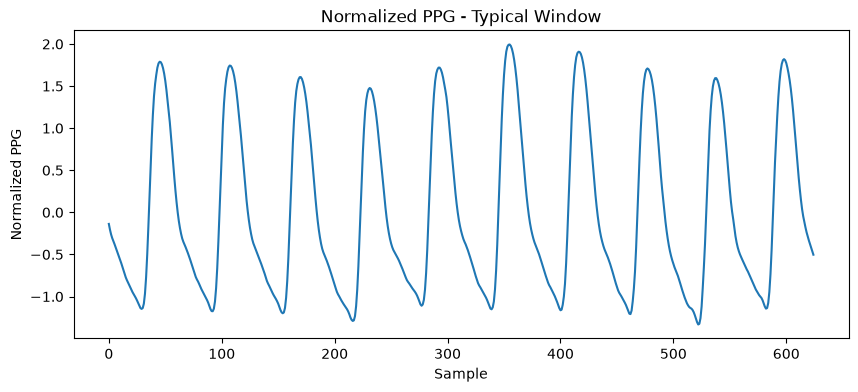

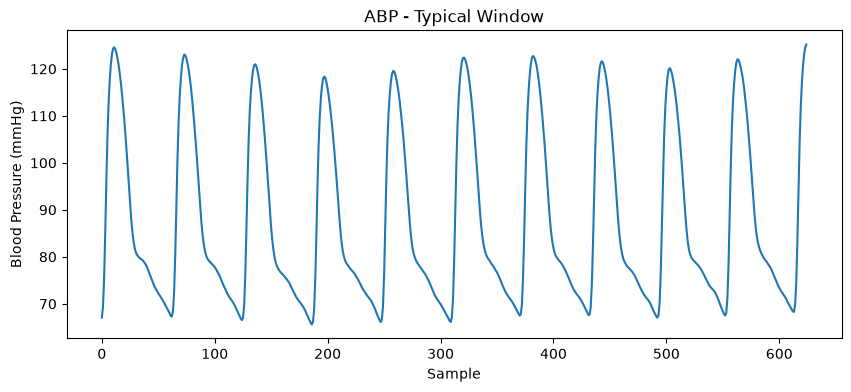


Part 2 Quality Investing
Window index: 0
Systolic: 100.91259404819084
Diastolic: 71.18640355337493


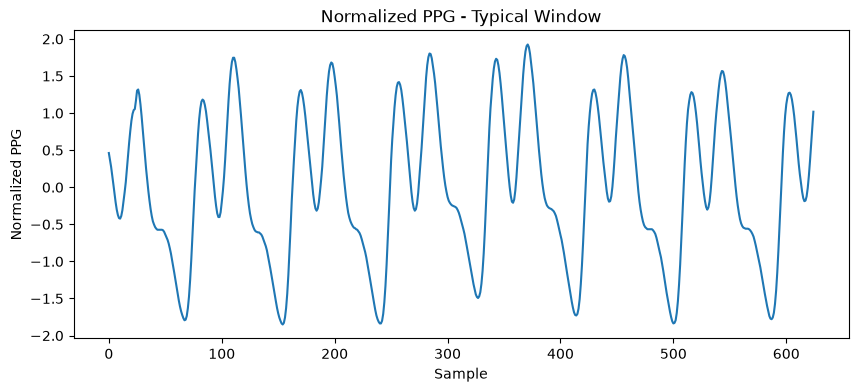

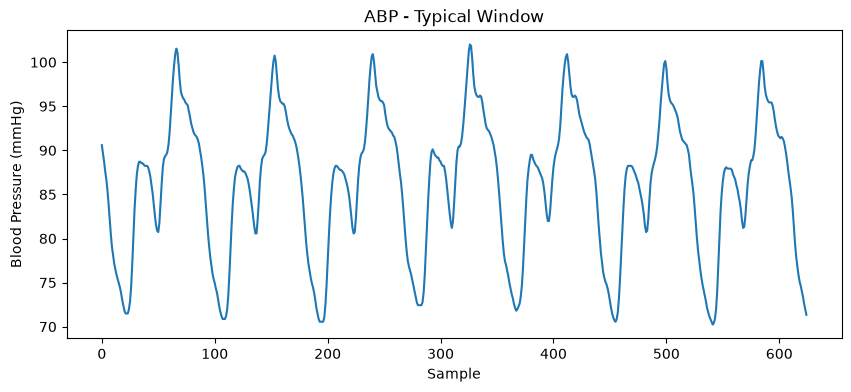


Part 3 Quality Investing
Window index: 0
Systolic: 125.35862148541165
Diastolic: 60.23471984010419


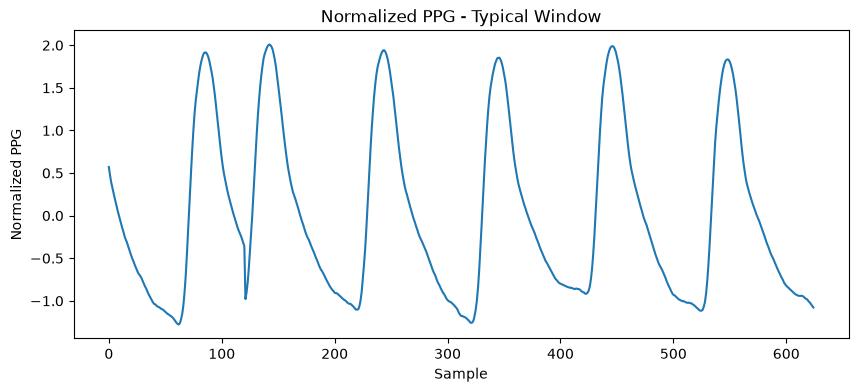

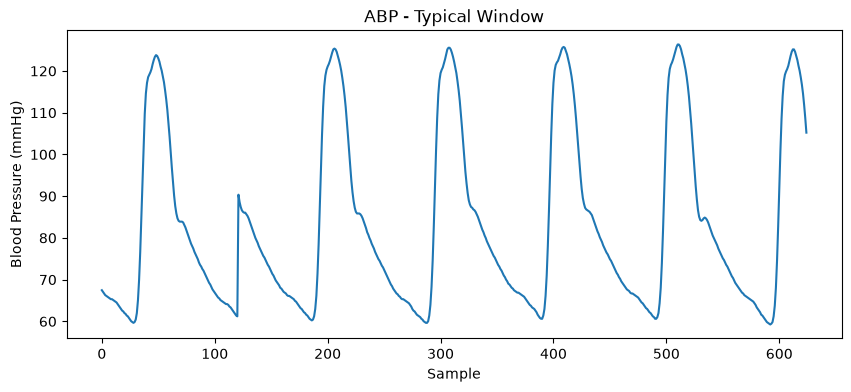


Part 4 Quality Investing
Window index: 0
Systolic: 108.48275558898663
Diastolic: 79.5670458597295


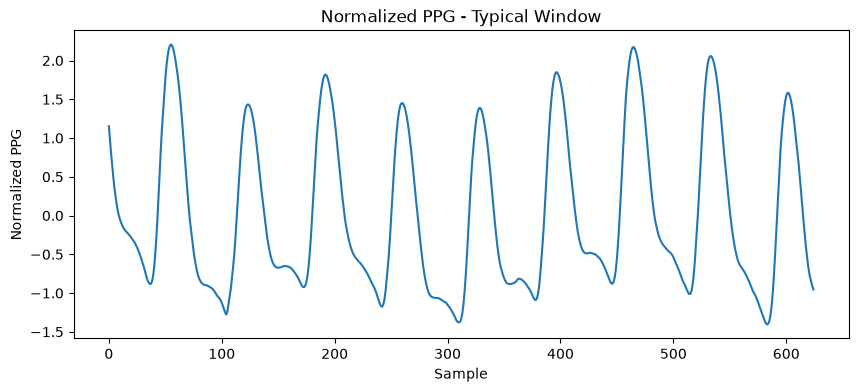

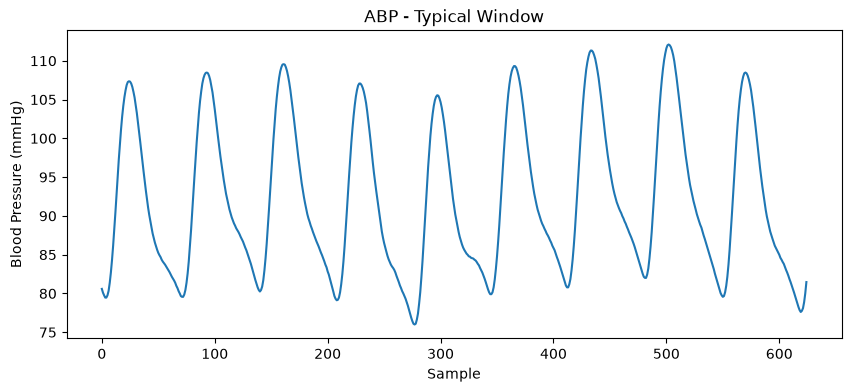

In [12]:
qualityInvesting(1, part1)
qualityInvesting(2, part2)
qualityInvesting(3, part3)
qualityInvesting(4, part4)

In [13]:
# Find a window with an unusually high diastolic label
def extremeBPInvesting(partNum, part):
    all_ppg_windows, all_abp_windows, all_systolic_labels, all_diastolic_labels = part
    extreme_indices = np.where(all_diastolic_labels > 120)[0]

    print("\n" + "=" * 60)
    print(f"Part {partNum} Extreme BP Investing")
    print("=" * 60)
    extreme_index = extreme_indices[0]

    print("Window index:", extreme_index)
    print("Systolic:", all_systolic_labels[extreme_index])
    print("Diastolic:", all_diastolic_labels[extreme_index])

    plt.figure(figsize=(10, 4))
    plt.plot(all_ppg_windows[extreme_index])

    plt.title("Normalized PPG - Extreme BP Window")
    plt.xlabel("Sample")
    plt.ylabel("Normalized PPG")
    plt.show()

    plt.figure(figsize=(10, 4))
    plt.plot(all_abp_windows[extreme_index])

    plt.title("ABP - Extreme BP Window")
    plt.xlabel("Sample")
    plt.ylabel("Blood Pressure (mmHg)")
    plt.show()


Part 1 Extreme BP Investing
Window index: 2939
Systolic: 175.63334418767545
Diastolic: 129.71019211991512


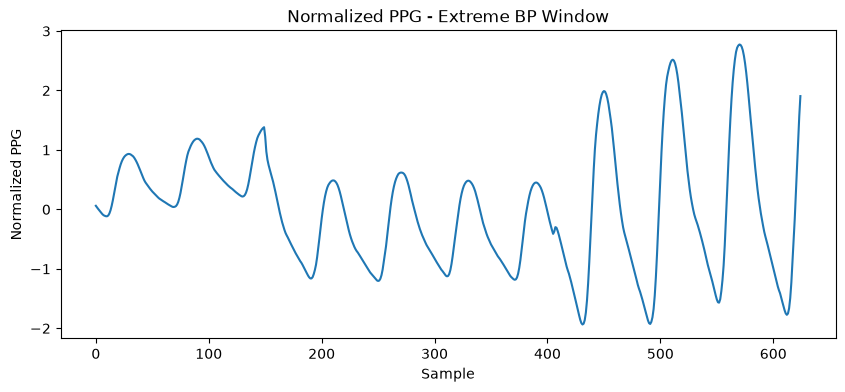

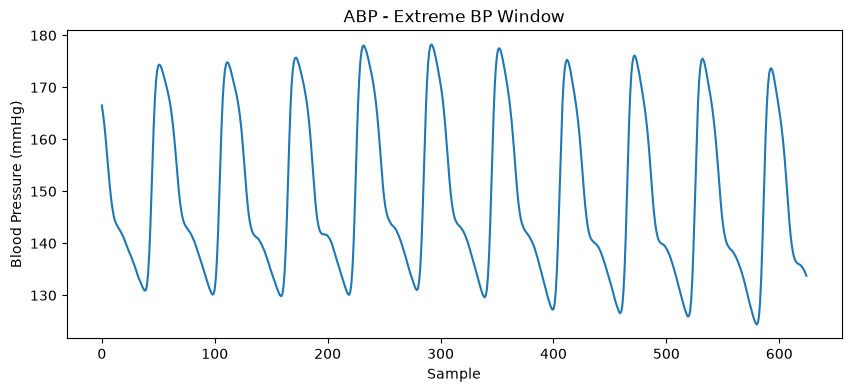


Part 2 Extreme BP Investing
Window index: 2604
Systolic: 144.26580544826143
Diastolic: 122.0417597145944


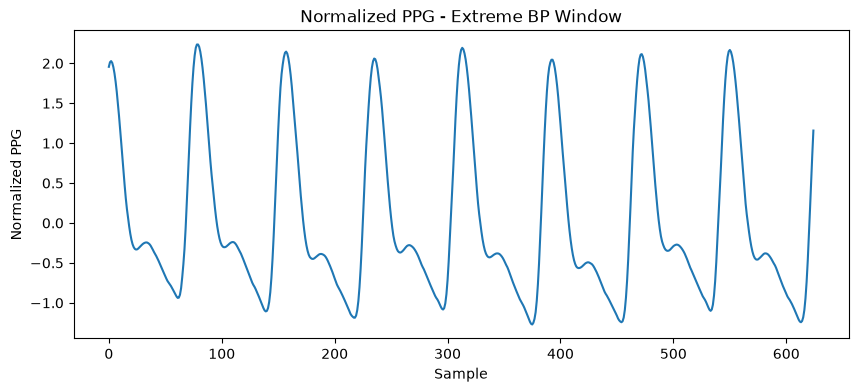

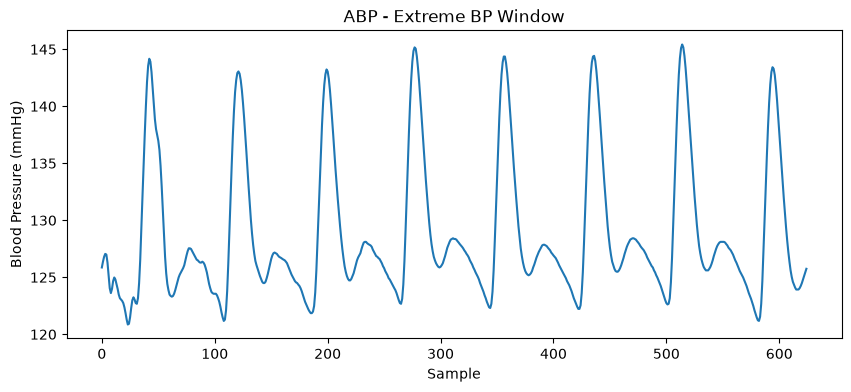


Part 3 Extreme BP Investing
Window index: 12219
Systolic: 141.25673558223957
Diastolic: 124.37626261639517


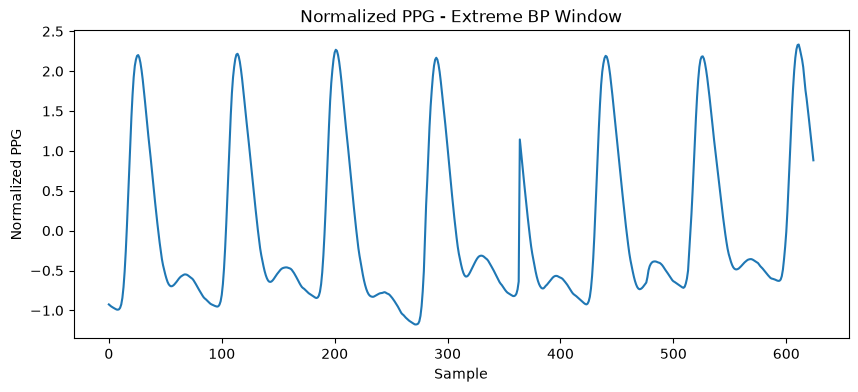

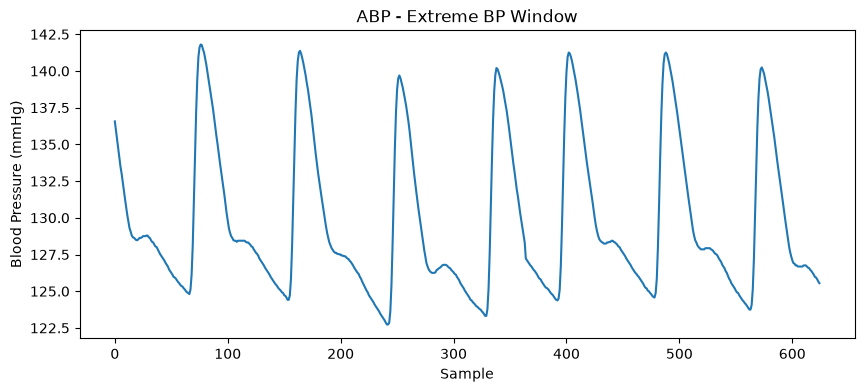


Part 4 Extreme BP Investing
Window index: 953
Systolic: 132.36752257818722
Diastolic: 120.93800217844706


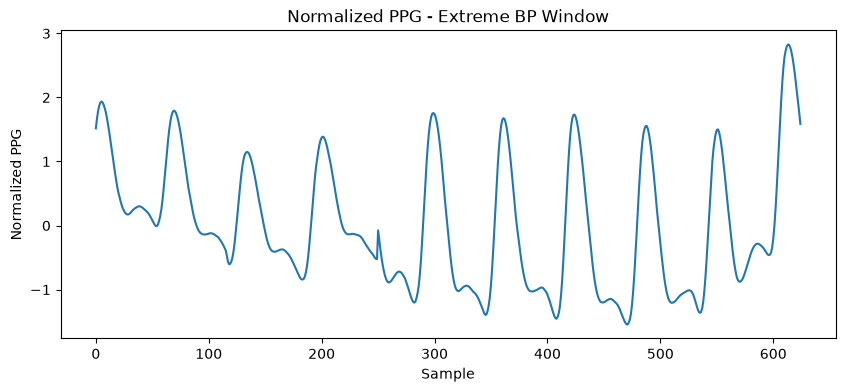

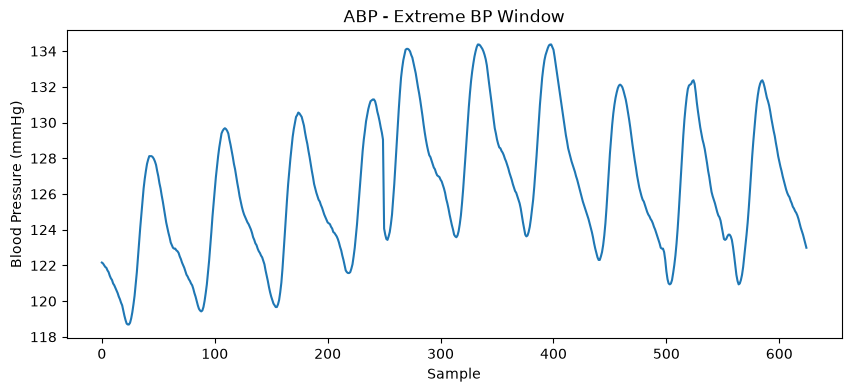

In [14]:
extremeBPInvesting(1, part1)
extremeBPInvesting(2, part2)
extremeBPInvesting(3, part3)
extremeBPInvesting(4, part4)

### Signal Quality Findings

The typical window showed clear repeating PPG and ABP waveforms. An example with an unusually high blood pressure label (approximately 175.94/128.56 mmHg) was also inspected. Although the PPG waveform showed more variation, the ABP signal maintained clear and repeating peaks and valleys.

This suggests that extreme blood pressure labels should not automatically be treated as outliers or removed based only on their blood pressure values. Signal quality should be considered separately when identifying noisy or unusable windows.


## Signal Quality Checks

Additional checks are used to identify potentially noisy or unusable PPG windows. Windows with extremely low variation or unusually large signal changes are flagged for further investigation rather than automatically removed.

In [15]:
def signalQualityCheck(partNum, part):
    all_ppg_windows, all_abp_windows, all_systolic_labels, all_diastolic_labels = part
    ppg_std_values = np.std(all_ppg_windows, axis=1)

    print("\n" + "=" * 60)
    print(f"Part {partNum} Signal Quality Check")
    print("=" * 60)
    ppg_max_changes = np.max(
        np.abs(np.diff(all_ppg_windows, axis=1)),
        axis=1
    )

    print("PPG standard deviation range:")
    print(np.min(ppg_std_values), "-", np.max(ppg_std_values))

    print("\nPPG maximum sample-to-sample change range:")
    print(np.min(ppg_max_changes), "-", np.max(ppg_max_changes))

    print("\nWindows with very large sample-to-sample changes:",
        np.sum(ppg_max_changes > 5))

In [16]:
signalQualityCheck(1, part1)
signalQualityCheck(2, part2)
signalQualityCheck(3, part3)
signalQualityCheck(4, part4)


Part 1 Signal Quality Check
PPG standard deviation range:
0.9999999999999997 - 1.0000000000000002

PPG maximum sample-to-sample change range:
0.11289664252941839 - 5.552345451598399

Windows with very large sample-to-sample changes: 5

Part 2 Signal Quality Check
PPG standard deviation range:
0.9999999999999997 - 1.0000000000000002

PPG maximum sample-to-sample change range:
0.14388445958877594 - 6.126496557671543

Windows with very large sample-to-sample changes: 4

Part 3 Signal Quality Check
PPG standard deviation range:
0.9999999999999997 - 1.0000000000000002

PPG maximum sample-to-sample change range:
0.11399127070882177 - 5.390714470231829

Windows with very large sample-to-sample changes: 3

Part 4 Signal Quality Check
PPG standard deviation range:
0.9999999999999997 - 1.0000000000000002

PPG maximum sample-to-sample change range:
0.13553545936927697 - 9.579362301890274

Windows with very large sample-to-sample changes: 6


### Suspicious PPG Windows

A small number of PPG windows showed unusually large changes between consecutive samples. These windows are inspected visually to determine whether they contain signal artifacts or valid pulse patterns.

In [17]:
def suspiciousPPGWindows(partNum, part):
    all_ppg_windows, all_abp_windows, all_systolic_labels, all_diastolic_labels = part
    ppg_max_changes = np.max(
        np.abs(np.diff(all_ppg_windows, axis=1)),
        axis=1
    )
    print("\n" + "=" * 60)
    print(f"Part {partNum} Suspicious PPG Windows")
    print("=" * 60)
    suspicious_indices = np.where(ppg_max_changes > 5)[0]

    print("Suspicious window indices:", suspicious_indices)
    print("Number of suspicious windows:", len(suspicious_indices))

    for index in suspicious_indices:

        print("\nWindow:", index)
        print("Systolic:", all_systolic_labels[index])
        print("Diastolic:", all_diastolic_labels[index])
        print("Maximum change:", ppg_max_changes[index])

        plt.figure(figsize=(10, 4))
        plt.plot(all_ppg_windows[index])

        plt.title(f"Suspicious PPG Window {index}")
        plt.xlabel("Sample")
        plt.ylabel("Normalized PPG")

        plt.show()


Part 1 Suspicious PPG Windows
Suspicious window indices: [ 42954  44476  48999  74576 122382]
Number of suspicious windows: 5

Window: 42954
Systolic: 145.115833793282
Diastolic: 70.53088656933666
Maximum change: 5.22129026635994


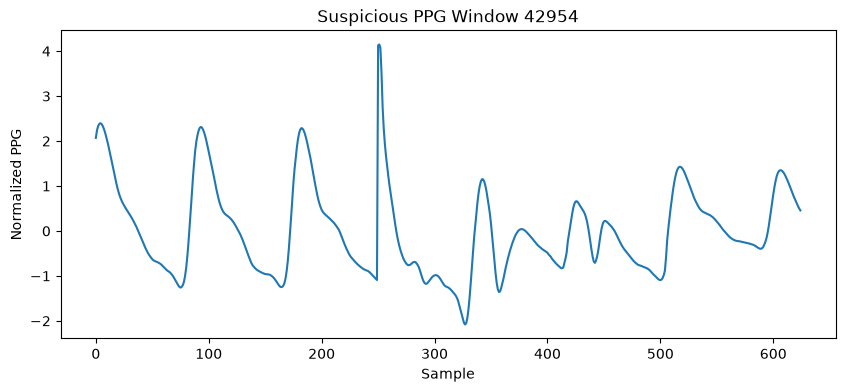


Window: 44476
Systolic: 119.0330821118237
Diastolic: 52.409723884278556
Maximum change: 5.552345451598399


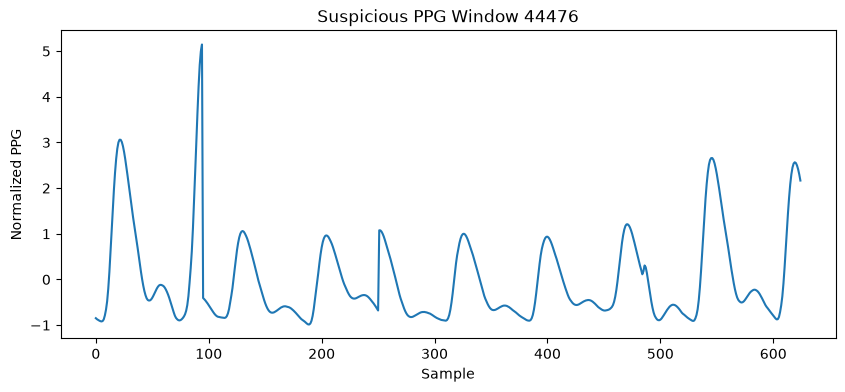


Window: 48999
Systolic: 169.12271104316355
Diastolic: 67.60024031299302
Maximum change: 5.025636257820555


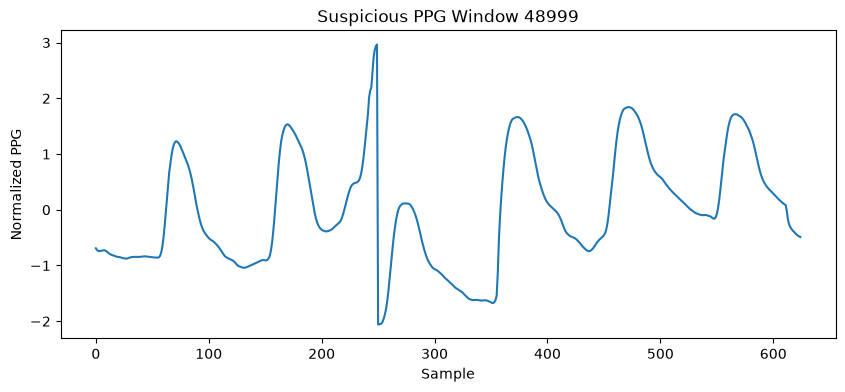


Window: 74576
Systolic: 138.61956792505362
Diastolic: 62.154122686621115
Maximum change: 5.0989262579287375


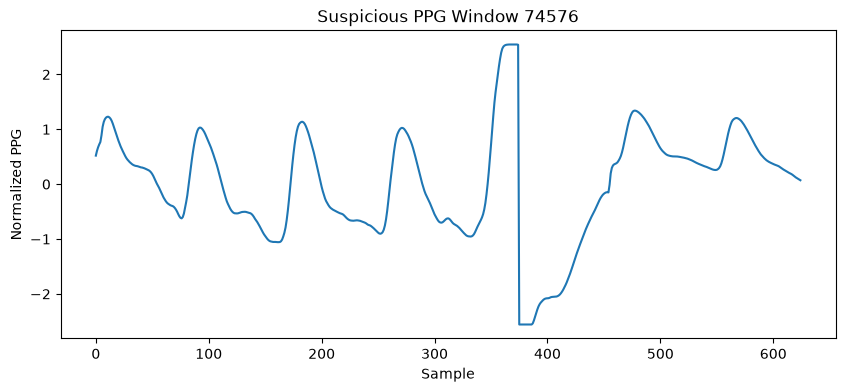


Window: 122382
Systolic: 129.8520512081589
Diastolic: 67.94214904289979
Maximum change: 5.389901704510089


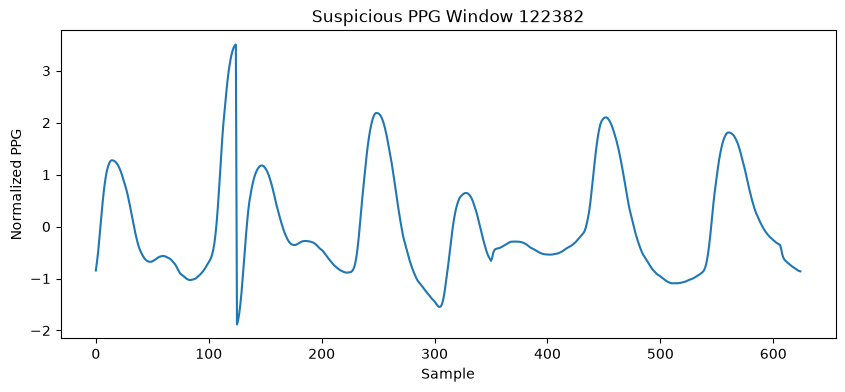


Part 2 Suspicious PPG Windows
Suspicious window indices: [ 13766  83843 100519 139477]
Number of suspicious windows: 4

Window: 13766
Systolic: 137.05615492522966
Diastolic: 106.30399699902704
Maximum change: 5.211504193598951


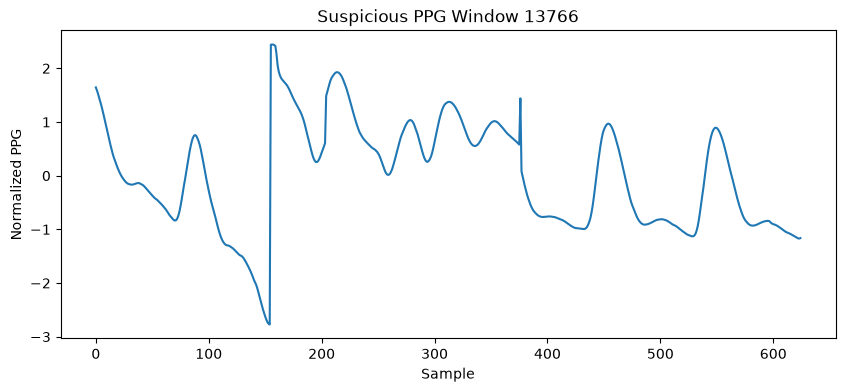


Window: 83843
Systolic: 136.99754217187603
Diastolic: 68.83091002160857
Maximum change: 5.761517923410683


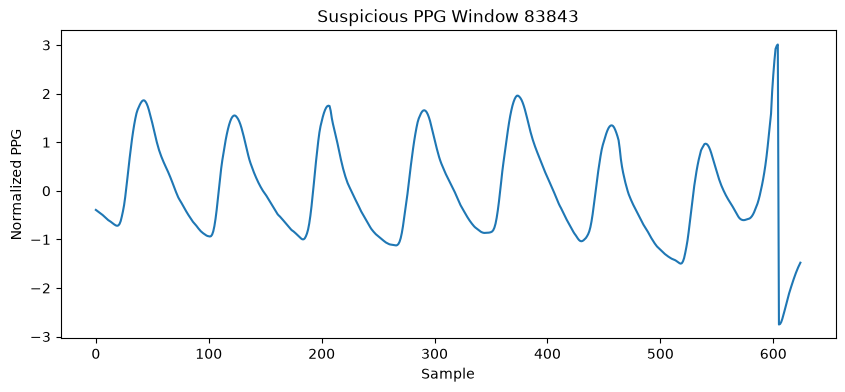


Window: 100519
Systolic: 139.04833053998078
Diastolic: 71.38205435596763
Maximum change: 6.126496557671543


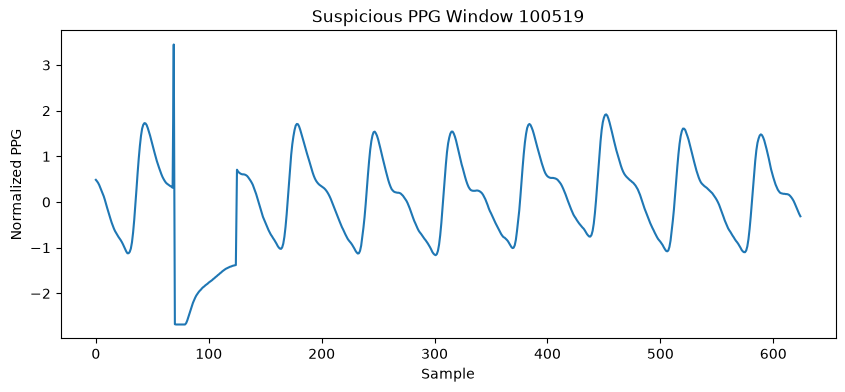


Window: 139477
Systolic: 145.40889841891635
Diastolic: 65.93954076773164
Maximum change: 5.512905144608411


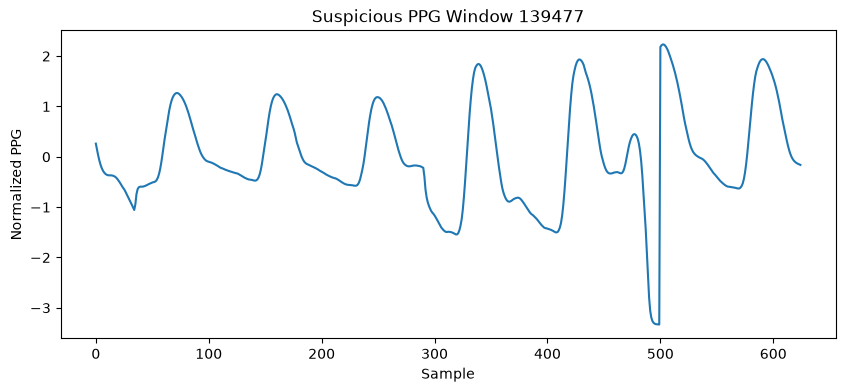


Part 3 Suspicious PPG Windows
Suspicious window indices: [ 1513 23819 38721]
Number of suspicious windows: 3

Window: 1513
Systolic: 103.45508699810104
Diastolic: 51.53197622684239
Maximum change: 5.075509602288072


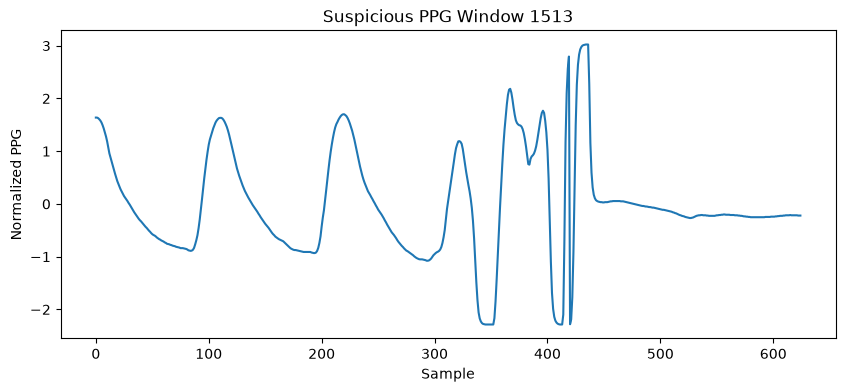


Window: 23819
Systolic: 92.11998065773471
Diastolic: 56.756849164521604
Maximum change: 5.202061772461985


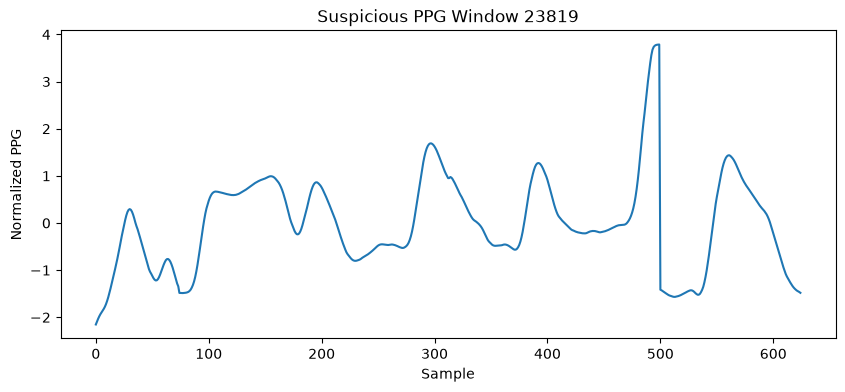


Window: 38721
Systolic: 139.93835874040826
Diastolic: 66.81873464463473
Maximum change: 5.390714470231829


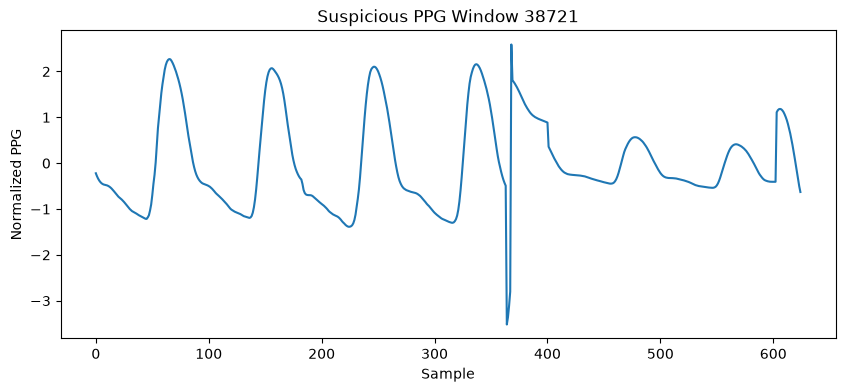


Part 4 Suspicious PPG Windows
Suspicious window indices: [ 25368  50500  77369  79609 104609 107947]
Number of suspicious windows: 6

Window: 25368
Systolic: 143.4551342480206
Diastolic: 101.10729584385517
Maximum change: 9.579362301890274


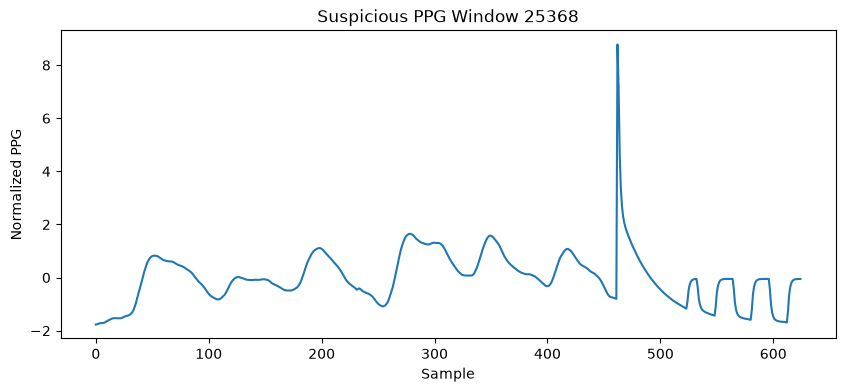


Window: 50500
Systolic: 111.2180254282407
Diastolic: 66.37913770618319
Maximum change: 5.243100579912177


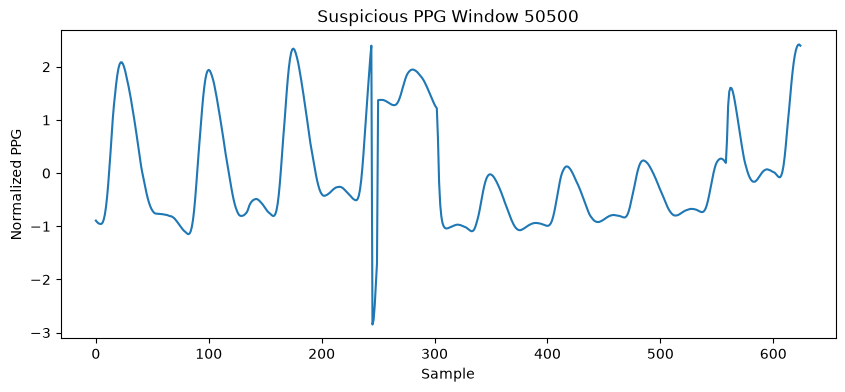


Window: 77369
Systolic: 123.38020739206675
Diastolic: 66.86757874890712
Maximum change: 6.994738747665182


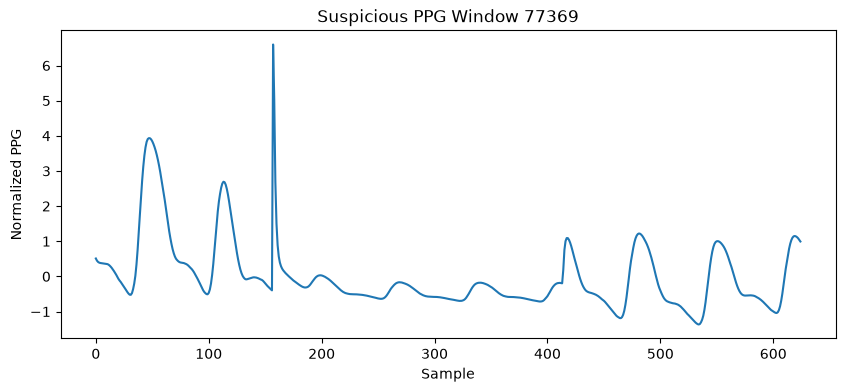


Window: 79609
Systolic: 121.57297553398818
Diastolic: 73.41268872140789
Maximum change: 6.075224926026204


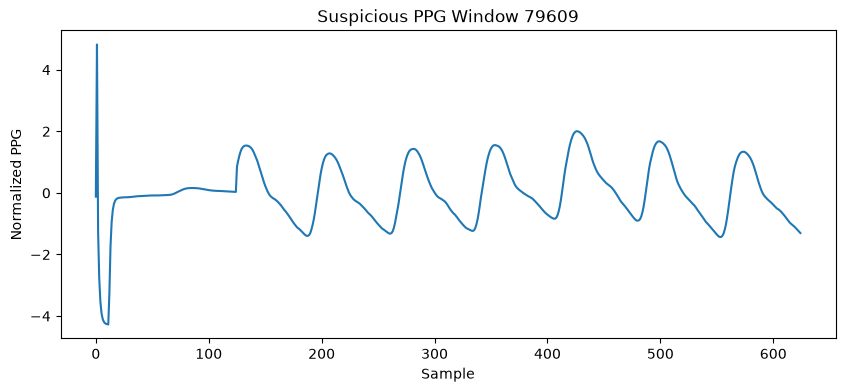


Window: 104609
Systolic: 128.48769784074173
Diastolic: 55.932239851525324
Maximum change: 5.848238076131502


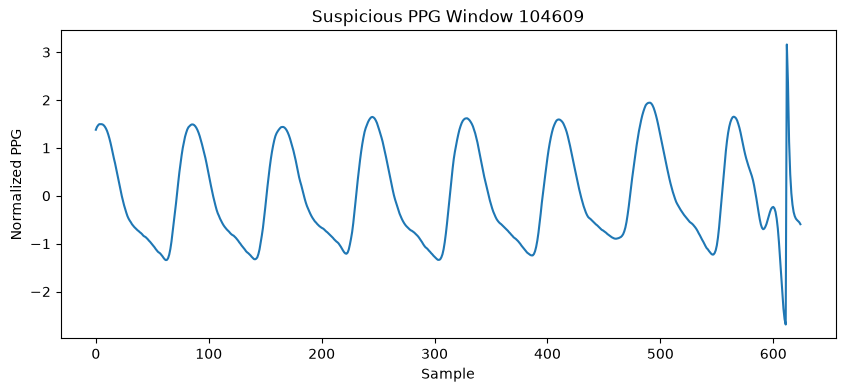


Window: 107947
Systolic: 127.19004752531347
Diastolic: 64.47421763955982
Maximum change: 5.282548396625231


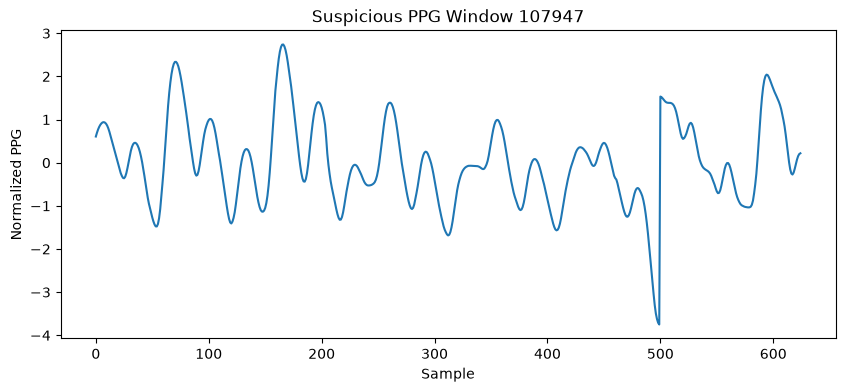

In [18]:
suspiciousPPGWindows(1, part1)
suspiciousPPGWindows(2, part2)
suspiciousPPGWindows(3, part3)
suspiciousPPGWindows(4, part4)

### PPG Signal Change Distribution

The distribution of maximum sample-to-sample changes is examined to understand whether the five flagged windows are isolated extreme cases compared with the rest of the dataset.

In [19]:
def ppgChangeDistribution(partNum, part):
    all_ppg_windows, all_abp_windows, all_systolic_labels, all_diastolic_labels = part
    ppg_max_changes = np.max(
        np.abs(np.diff(all_ppg_windows, axis=1)),
        axis=1
    )
    print("\n" + "=" * 60)
    print(f"Part {partNum} PPG Change Distribution")
    print("=" * 60)
    plt.figure(figsize=(8, 5))

    plt.hist(ppg_max_changes, bins=100)

    plt.xlabel("Maximum Sample-to-Sample Change")
    plt.ylabel("Number of Windows")
    plt.title("Distribution of Maximum PPG Changes")

    plt.show()

    print("95th percentile:", np.percentile(ppg_max_changes, 95))
    print("99th percentile:", np.percentile(ppg_max_changes, 99))
    print("99.9th percentile:", np.percentile(ppg_max_changes, 99.9))
    print("Maximum:", np.max(ppg_max_changes))


Part 1 PPG Change Distribution


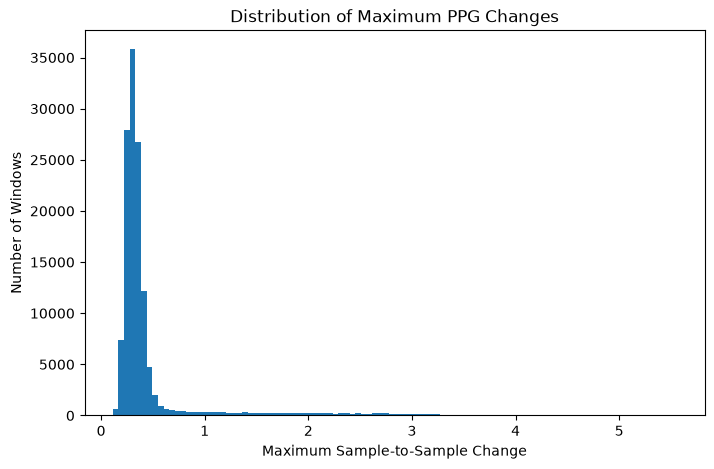

95th percentile: 1.5617252846966863
99th percentile: 2.903155841071698
99.9th percentile: 3.5411052353949914
Maximum: 5.552345451598399

Part 2 PPG Change Distribution


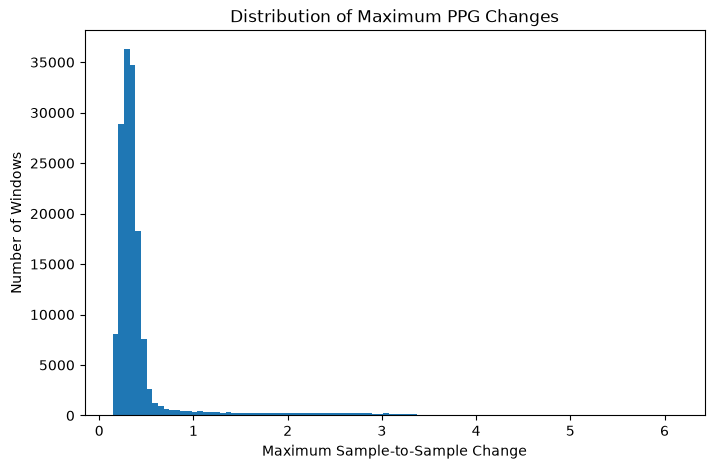

95th percentile: 1.4464873265723173
99th percentile: 2.9392757076622207
99.9th percentile: 3.5993485062618964
Maximum: 6.126496557671543

Part 3 PPG Change Distribution


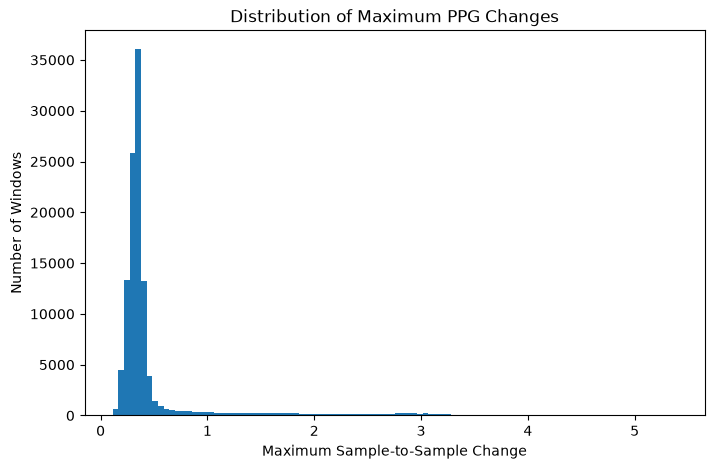

95th percentile: 1.7479131319016339
99th percentile: 3.0321723362093045
99.9th percentile: 3.6186417760982112
Maximum: 5.390714470231829

Part 4 PPG Change Distribution


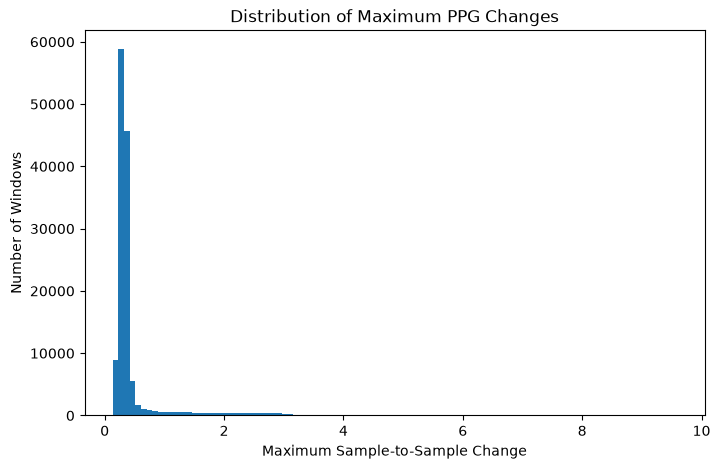

95th percentile: 1.5815978559601302
99th percentile: 2.8366666253680917
99.9th percentile: 3.585209777924626
Maximum: 9.579362301890274


In [20]:
ppgChangeDistribution(1, part1)
ppgChangeDistribution(2, part2)
ppgChangeDistribution(3, part3)
ppgChangeDistribution(4, part4)

### Signal Quality Findings

Most PPG windows had relatively small sample-to-sample changes. The 95th percentile was approximately 1.56, the 99th percentile was 2.90, and the 99.9th percentile was 3.54. Only five windows had a maximum change greater than 5.

Visual inspection of these five windows showed abrupt jumps or spikes that differed from the typical repeating PPG waveform. These five windows were treated as likely signal artifacts and removed. Blood pressure values were not removed simply because they were unusually high or low.

## Remove Noisy PPG Windows

The five PPG windows identified as likely signal artifacts are removed while keeping the PPG, ABP, systolic, and diastolic data aligned.

In [21]:
def removeNoisyWindows(partNum, part):
    all_ppg_windows, all_abp_windows, all_systolic_labels, all_diastolic_labels = part
    ppg_max_changes = np.max(
        np.abs(np.diff(all_ppg_windows, axis=1)),
        axis=1
    )
    print("\n" + "=" * 60)
    print(f"Part {partNum} Remove Noisy Windows")
    print("=" * 60)
    noise_mask = ppg_max_changes <= 5

    clean_ppg_windows = all_ppg_windows[noise_mask]
    clean_abp_windows = all_abp_windows[noise_mask]
    clean_systolic_labels = all_systolic_labels[noise_mask]
    clean_diastolic_labels = all_diastolic_labels[noise_mask]

    print("Examples before filtering:", len(all_ppg_windows))
    print("Noisy windows removed:", np.sum(~noise_mask))
    print("Examples after filtering:", len(clean_ppg_windows))

In [22]:
removeNoisyWindows(1, part1)
removeNoisyWindows(2, part2)
removeNoisyWindows(3, part3)
removeNoisyWindows(4, part4)


Part 1 Remove Noisy Windows
Examples before filtering: 131162
Noisy windows removed: 5
Examples after filtering: 131157

Part 2 Remove Noisy Windows
Examples before filtering: 151304
Noisy windows removed: 4
Examples after filtering: 151300

Part 3 Remove Noisy Windows
Examples before filtering: 112449
Noisy windows removed: 3
Examples after filtering: 112446

Part 4 Remove Noisy Windows
Examples before filtering: 133910
Noisy windows removed: 6
Examples after filtering: 133904


## Final Cleaned Dataset

In [23]:
def cleanDataset(partNum, part):
    all_ppg_windows, all_abp_windows, all_systolic_labels, all_diastolic_labels = part
    ppg_max_changes = np.max(
        np.abs(np.diff(all_ppg_windows, axis=1)),
        axis=1
    )
    noise_mask = ppg_max_changes <= 5

    clean_ppg_windows = all_ppg_windows[noise_mask]
    clean_abp_windows = all_abp_windows[noise_mask]
    clean_systolic_labels = all_systolic_labels[noise_mask]
    clean_diastolic_labels = all_diastolic_labels[noise_mask]
    

    
    print("\n" + "=" * 60)
    print(f"Part {partNum} Final Cleaned Dataset")
    print("=" * 60)

    print("PPG windows:", clean_ppg_windows.shape)
    print("ABP windows:", clean_abp_windows.shape)
    print("Systolic labels:", clean_systolic_labels.shape)
    print("Diastolic labels:", clean_diastolic_labels.shape)

    print("\n--- Final Blood Pressure Statistics ---")

    print("Mean systolic:", np.mean(clean_systolic_labels))
    print("Systolic standard deviation:", np.std(clean_systolic_labels))
    print("Minimum systolic:", np.min(clean_systolic_labels))
    print("Maximum systolic:", np.max(clean_systolic_labels))

    print("\nMean diastolic:", np.mean(clean_diastolic_labels))
    print("Diastolic standard deviation:", np.std(clean_diastolic_labels))
    print("Minimum diastolic:", np.min(clean_diastolic_labels))
    print("Maximum diastolic:", np.max(clean_diastolic_labels))

    print("\n--- Normalization Check ---")

    print("First PPG window mean:", np.mean(clean_ppg_windows[0]))
    print("First PPG window standard deviation:", np.std(clean_ppg_windows[0]))
    return clean_ppg_windows, clean_abp_windows, clean_systolic_labels, clean_diastolic_labels

In [24]:
clean_part1 = cleanDataset(1, part1)
clean_part2 = cleanDataset(2, part2)
clean_part3 = cleanDataset(3, part3)
clean_part4 = cleanDataset(4, part4)


Part 1 Final Cleaned Dataset
PPG windows: (131157, 625)
ABP windows: (131157, 625)
Systolic labels: (131157,)
Diastolic labels: (131157,)

--- Final Blood Pressure Statistics ---
Mean systolic: 132.33652721403246
Systolic standard deviation: 23.42372042347597
Minimum systolic: 56.00459524884093
Maximum systolic: 199.28375075464066

Mean diastolic: 66.56751746080926
Diastolic standard deviation: 11.527233742659325
Minimum diastolic: 50.0
Maximum diastolic: 186.78003719970616

--- Normalization Check ---
First PPG window mean: 7.105427357601002e-17
First PPG window standard deviation: 1.0

Part 2 Final Cleaned Dataset
PPG windows: (151300, 625)
ABP windows: (151300, 625)
Systolic labels: (151300,)
Diastolic labels: (151300,)

--- Final Blood Pressure Statistics ---
Mean systolic: 128.70154524183613
Systolic standard deviation: 21.977601929923786
Minimum systolic: 60.2592216220071
Maximum systolic: 199.63542796185476

Mean diastolic: 68.32855093994367
Diastolic standard deviation: 12.516

## Milestone 1 Preprocessing Summary

Part 1 of the Cuff-less Blood Pressure dataset contained 3,000 physiological signal records. The PPG and ABP signals were extracted and divided into non-overlapping 5-second windows containing 625 samples each.

The data was checked for missing, infinite, and invalid values, and no invalid records were found. Systolic and diastolic blood pressure labels were generated using peaks and valleys from the ABP signal. One window was skipped because valid peaks or valleys could not be detected.

Each PPG window was normalized using z-score normalization. The normalization check produced a mean approximately equal to 0 and a standard deviation of 1.

Blood pressure ranges and distributions were also investigated. The cleaned dataset had a mean systolic pressure of approximately 130.54 mmHg with a standard deviation of 22.97 mmHg, and a mean diastolic pressure of approximately 67.22 mmHg with a standard deviation of 11.60 mmHg. Extreme blood pressure values were investigated but were not automatically removed based only on their BP values.

Signal quality was evaluated using the maximum sample-to-sample change in each normalized PPG window. Five windows showed unusually large abrupt changes and visual inspection showed spikes or discontinuities compared with typical PPG waveforms. These five windows were removed as likely signal artifacts.

After preprocessing and signal-quality filtering, the final Part 1 dataset contains 131,157 normalized PPG windows with matching ABP signals and systolic and diastolic labels. The cleaned data is ready for feature engineering and model development.

## Milestone 2 — Model Development

### Objective
Use features extracted from PPG signals to estimate systolic (SBP) and diastolic (DBP) blood pressure.

Each PPG window contains five seconds of signal data sampled at 125 Hz.

Five features are extracted:
- Pulse amplitude
- Rise time
- Fall time
- Pulse width at 50% prominence
- Signal skewness

The corresponding blood pressure labels are derived from the ABP signal.


In [26]:
import numpy as np
import pandas as pd

from scipy.signal import find_peaks, peak_widths
from scipy.stats import skew

def extract_features(ppg_windows, fs=125):
    rows = []

    for signal in ppg_windows:
        signal = np.asarray(signal, dtype=float)

        peaks, _ = find_peaks(
            signal,
            distance=int(0.4 * fs),
            prominence=0.3
        )

        troughs, _ = find_peaks(
            -signal,
            distance=int(0.4 * fs),
            prominence=0.3
        )

        amplitudes = []
        rise_times = []
        fall_times = []
        widths = []

        for peak in peaks:
            before = troughs[troughs < peak]
            after = troughs[troughs > peak]

            if len(before) == 0 or len(after) == 0:
                continue

            left = before[-1]
            right = after[0]

            amplitude = signal[peak] - signal[left]

            if amplitude <= 0:
                continue

            amplitudes.append(amplitude)
            rise_times.append((peak - left) / fs)
            fall_times.append((right - peak) / fs)

            width = peak_widths(
                signal,
                [peak],
                rel_height=0.5
            )[0][0] / fs

            widths.append(width)

        rows.append({
            "pulse_amplitude": np.mean(amplitudes) if amplitudes else np.nan,
            "rise_time": np.mean(rise_times) if rise_times else np.nan,
            "fall_time": np.mean(fall_times) if fall_times else np.nan,
            "pulse_width_50": np.mean(widths) if widths else np.nan,
            "skewness": skew(signal)
        })

    return pd.DataFrame(rows)

In [27]:
clean_parts = [
    clean_part1,
    clean_part2,
    clean_part3,
    clean_part4
]


In [28]:
from pathlib import Path

ROOT = Path.cwd()

while ROOT != ROOT.parent and not (ROOT / "data" / "Part_1.mat").exists():
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data"

if not (DATA_DIR / "Part_1.mat").exists():
    raise FileNotFoundError("Could not find the dataset folder.")


### Recording ID Reconstruction

The shared preprocessing pipeline produces cleaned PPG windows and blood-pressure labels but does not retain their original recording identifiers.

To support recording-level train/test splitting, we reconstruct recording IDs from the original MATLAB records using the same windowing and filtering rules.

These identifiers are used only to separate recordings during model evaluation. They are not used as prediction features.

In [29]:

import mat73
import numpy as np
from scipy.signal import find_peaks

def reconstruct_recording_ids(part_number, expected_count):

    file_path = DATA_DIR / f"Part_{part_number}.mat"
    data = mat73.loadmat(file_path)
    records = data[f"Part_{part_number}"]

    recording_ids = []
    window_size = 625

    for record_index in range(len(records)):

        record = np.asarray(records[record_index])
        ppg = record[0]
        abp = record[1]

        if not np.all(np.isfinite(ppg)) or not np.all(np.isfinite(abp)):
            continue

        num_windows = len(ppg) // window_size

        ppg_windows = ppg[:num_windows * window_size].reshape(
            num_windows, window_size
        )

        abp_windows = abp[:num_windows * window_size].reshape(
            num_windows, window_size
        )

        ppg_stds = np.std(ppg_windows, axis=1)

        for j in range(num_windows):

            if ppg_stds[j] == 0:
                continue

            abp_window = abp_windows[j]

            peaks, _ = find_peaks(abp_window, distance=50)
            valleys, _ = find_peaks(-abp_window, distance=50)

            if len(peaks) == 0 or len(valleys) == 0:
                continue

            normalized_ppg = (
                ppg_windows[j] - np.mean(ppg_windows[j])
            ) / ppg_stds[j]

            max_change = np.max(
                np.abs(np.diff(normalized_ppg))
            )

            if max_change > 5:
                continue

            recording_ids.append(
                f"{part_number}_{record_index}"
            )

    recording_ids = np.asarray(recording_ids)

    if len(recording_ids) != expected_count:
        raise ValueError(
            f"Part {part_number}: Expected {expected_count} windows, "
            f"but reconstructed {len(recording_ids)}."
        )

    return recording_ids


In [30]:

groups_parts = []

for part_number, part in enumerate(clean_parts, start=1):

    print(f"Reconstructing Part {part_number}...")

    ids = reconstruct_recording_ids(
        part_number,
        len(part[0])
    )

    groups_parts.append(ids)

    print(
        f"Windows: {len(ids)}, "
        f"Unique recordings: {len(np.unique(ids))}"
    )

groups = np.concatenate(groups_parts)

print("\nTotal windows:", len(groups))
print("Unique recording groups:", len(np.unique(groups)))


Reconstructing Part 1...
Windows: 131157, Unique recordings: 2999
Reconstructing Part 2...
Windows: 151300, Unique recordings: 3000
Reconstructing Part 3...
Windows: 112446, Unique recordings: 3000
Reconstructing Part 4...
Windows: 133904, Unique recordings: 2999

Total windows: 528807
Unique recording groups: 11998


## Preparing the Machine Learning Dataset

The cleaned PPG signals are converted into numerical features that XGBoost can use for regression.

Each row represents one five-second PPG window and contains five waveform features. The corresponding SBP and DBP values serve as prediction targets.

Recording IDs are retained separately to support recording-level splitting and reduce data leakage.

In [31]:
X_parts = []
y_parts = []

for clean_ppg, clean_abp, sbp, dbp in clean_parts:

    features = extract_features(clean_ppg)

    labels = pd.DataFrame({
        "SBP": np.asarray(sbp).ravel(),
        "DBP": np.asarray(dbp).ravel()
    })

    X_parts.append(features)
    y_parts.append(labels)

X = pd.concat(X_parts, ignore_index=True)
y = pd.concat(y_parts, ignore_index=True)

assert len(X) == len(y) == len(groups)

print("Features:", X.shape)
print("Labels:", y.shape)
print("Recording groups:", groups.shape)

Features: (528807, 5)
Labels: (528807, 2)
Recording groups: (528807,)


## Training, Validation, and Test Split

The dataset is divided into three subsets:

- **Training (60%)** — Used to teach XGBoost the relationship between PPG features and blood pressure.
- **Validation (20%)** — Used to evaluate training progress and select model settings.
- **Testing (20%)** — Reserved for final evaluation on unseen recordings.

We use `GroupShuffleSplit` so windows from the same recording do not appear in multiple subsets. This reduces data leakage and makes the evaluation more reliable.


In [33]:
from sklearn.model_selection import GroupShuffleSplit

# Split 1: Training (60%) and remaining data (40%)
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.40,
    random_state=42
)

train_idx, remaining_idx = next(
    split1.split(X, y, groups=groups)
)

# Split 2: Divide remaining data into validation and testing
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_relative, test_relative = next(
    split2.split(
        X.iloc[remaining_idx],
        y.iloc[remaining_idx],
        groups=groups[remaining_idx]
    )
)

val_idx = remaining_idx[val_relative]
test_idx = remaining_idx[test_relative]

# Features
X_train = X.iloc[train_idx]
X_val = X.iloc[val_idx]
X_test = X.iloc[test_idx]

# Blood pressure labels
y_train = y.iloc[train_idx]
y_val = y.iloc[val_idx]
y_test = y.iloc[test_idx]

# Verify no recording overlap
train_groups = set(groups[train_idx])
val_groups = set(groups[val_idx])
test_groups = set(groups[test_idx])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)
print("Recording-level split verified.")

Training: (319853, 5)
Validation: (104396, 5)
Testing: (104558, 5)
Recording-level split verified.


## XGBoost Model Training

XGBoost (Extreme Gradient Boosting) is an ensemble learning algorithm that combines multiple decision trees to make predictions.

We train two regression models:

- **SBP model:** Predicts systolic blood pressure.
- **DBP model:** Predicts diastolic blood pressure.

Each model learns from five PPG waveform features.

### Training Configuration

- `n_estimators=500`: Maximum number of boosting rounds.
- `max_depth=5`: Limits the complexity of individual trees.
- `learning_rate=0.05`: Controls how much each new tree contributes.
- `tree_method="hist"`: Uses histogram-based training for computational efficiency.
- `early_stopping_rounds=30`: Stops training when validation performance fails to improve for 30 rounds.

The validation set is used for early stopping, while the test set remains reserved for final evaluation.

In [35]:
from xgboost import XGBRegressor
import time

xgb_models = {}

for target in ["SBP", "DBP"]:

    print(f"Training XGBoost for {target}...")

    start_time = time.time()

    model = XGBRegressor(
        n_estimators=500,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.9,
        objective="reg:squarederror",
        tree_method="hist",
        eval_metric="mae",
        early_stopping_rounds=30,
        n_jobs=4,
        random_state=42
    )

    model.fit(
        X_train,
        y_train[target],
        eval_set=[(X_val, y_val[target])],
        verbose=False
    )

    xgb_models[target] = model

    elapsed = time.time() - start_time

    print(f"Training completed in {elapsed:.2f} seconds")
    print(f"Best iteration: {model.best_iteration}")
    print()

Training XGBoost for SBP...
Training completed in 1.82 seconds
Best iteration: 498

Training XGBoost for DBP...
Training completed in 1.35 seconds
Best iteration: 499



## XGBoost Model Evaluation

After training, we evaluate both models using the held-out test dataset.

We measure prediction accuracy using:

- **Mean Absolute Error (MAE):** Average absolute difference between predicted and actual blood pressure.
- **Root Mean Squared Error (RMSE):** Measures prediction error while penalizing larger errors more heavily.
- **R² Score:** Measures how well the model explains variation in blood pressure.

MAE and RMSE are reported in mmHg. Lower values indicate better performance.

The test dataset contains 104,558 PPG windows from recordings excluded from training and validation.

In [36]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

xgb_predictions = {}
results = []

for target in ["SBP", "DBP"]:

    actual = y_test[target]
    predicted = xgb_models[target].predict(X_test)

    xgb_predictions[target] = predicted

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    results.append({
        "Model": "XGBoost",
        "Target": target,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    print(f"{target} Results:")
    print(f"MAE: {mae:.2f} mmHg")
    print(f"RMSE: {rmse:.2f} mmHg")
    print(f"R²: {r2:.3f}")
    print()

xgb_results = pd.DataFrame(results)
display(xgb_results.round(3))

SBP Results:
MAE: 16.38 mmHg
RMSE: 20.82 mmHg
R²: 0.149

DBP Results:
MAE: 7.99 mmHg
RMSE: 10.89 mmHg
R²: 0.101



,Model,Target,MAE,RMSE,R2
0,XGBoost,SBP,16.382,20.819,0.149
1,XGBoost,DBP,7.988,10.886,0.101


## Baseline Model Comparison

Our baseline predicts the mean blood pressure from the training dataset for every test sample.

We compare the baseline and XGBoost using the same held-out test data and the same evaluation metrics.

If XGBoost achieves lower MAE and RMSE than the baseline, it demonstrates improvement over constant mean prediction.

In [37]:
baseline_results = []

for target in ["SBP", "DBP"]:

    # Calculate mean using training data only
    mean_bp = y_train[target].mean()

    # Predict the same value for every test window
    baseline_predictions = np.full(
        len(y_test),
        mean_bp
    )

    mae = mean_absolute_error(
        y_test[target],
        baseline_predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test[target],
            baseline_predictions
        )
    )

    r2 = r2_score(
        y_test[target],
        baseline_predictions
    )

    baseline_results.append({
        "Model": "Mean Baseline",
        "Target": target,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

baseline_df = pd.DataFrame(baseline_results)

comparison_table = pd.concat(
    [baseline_df, xgb_results],
    ignore_index=True
)

display(comparison_table.round(3))

,Model,Target,MAE,RMSE,R2
0,Mean Baseline,SBP,18.335,22.583,-0.001
1,Mean Baseline,DBP,8.689,11.480,-0.000
2,XGBoost,SBP,16.382,20.819,0.149
3,XGBoost,DBP,7.988,10.886,0.101


## XGBoost Feature Importance

Feature importance helps identify which PPG waveform characteristics contribute most to the model's predictions.

We examine five extracted features:

- Pulse amplitude
- Rise time
- Fall time
- Pulse width at 50% amplitude
- Skewness

We compare feature importance separately for systolic and diastolic blood pressure.


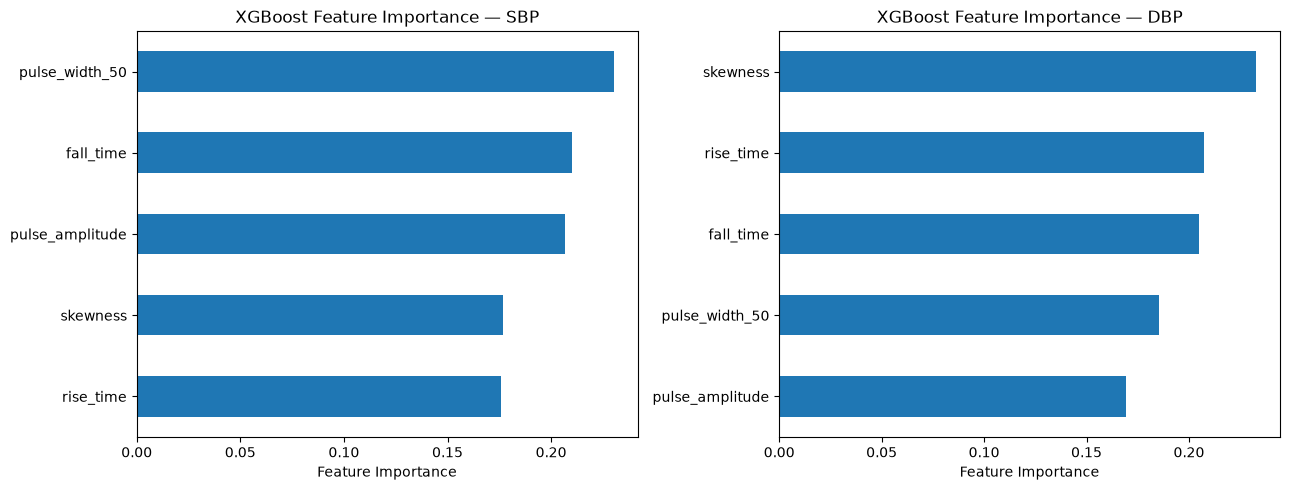

In [38]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, target in zip(axes, ["SBP", "DBP"]):

    importance = pd.Series(
        xgb_models[target].feature_importances_,
        index=X_train.columns
    ).sort_values()

    importance.plot(
        kind="barh",
        ax=ax
    )

    ax.set_title(f"XGBoost Feature Importance — {target}")
    ax.set_xlabel("Feature Importance")

plt.tight_layout()
plt.show()

### Feature Importance Interpretation

The XGBoost models assign different importance levels to the extracted PPG features.

For systolic blood pressure, pulse width at 50% amplitude has the highest importance, followed by fall time and pulse amplitude.

For diastolic blood pressure, skewness has the highest importance, followed by rise time and fall time.


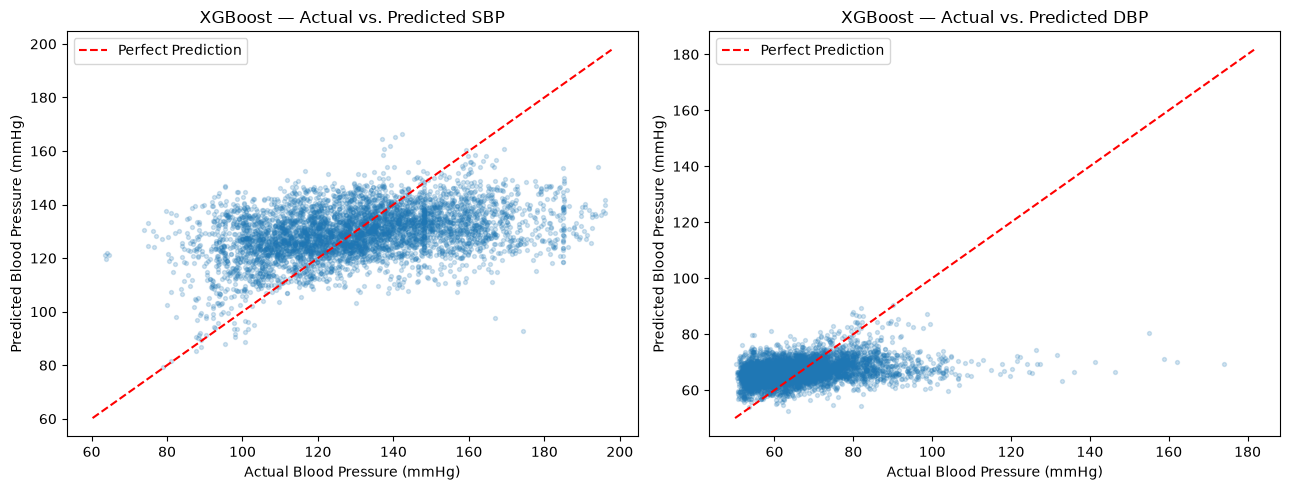

In [39]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, target in zip(axes, ["SBP", "DBP"]):

    actual = y_test[target].to_numpy()
    predicted = xgb_predictions[target]

    # Sample points to keep the chart readable
    rng = np.random.default_rng(42)
    indices = rng.choice(
        len(actual),
        size=min(5000, len(actual)),
        replace=False
    )

    ax.scatter(
        actual[indices],
        predicted[indices],
        alpha=0.2,
        s=8
    )

    lower = min(actual.min(), predicted.min())
    upper = max(actual.max(), predicted.max())

    ax.plot(
        [lower, upper],
        [lower, upper],
        "r--",
        label="Perfect Prediction"
    )

    ax.set_title(f"XGBoost — Actual vs. Predicted {target}")
    ax.set_xlabel("Actual Blood Pressure (mmHg)")
    ax.set_ylabel("Predicted Blood Pressure (mmHg)")
    ax.legend()

plt.tight_layout()
plt.show()

### Prediction Visualization Interpretation

The actual-versus-predicted plots show that XGBoost captures some relationships between PPG waveform features and blood pressure, but predictions remain concentrated around typical values.

Both models tend to overestimate lower blood pressure readings and underestimate higher readings.

This indicates that the current five-feature approach has limited ability to capture the full range of blood pressure variation.


## Milestone 2 — XGBoost Model Performance Summary

### Model Evaluation

The XGBoost models were trained to estimate systolic (SBP) and diastolic (DBP) blood pressure using five features extracted from PPG waveforms. The models were evaluated on a held-out test dataset containing 104,558 windows, using recording-level separation to reduce data leakage.

| Metric | SBP | DBP |
|---|---:|---:|
| MAE | 16.38 mmHg | 7.99 mmHg |
| RMSE | 20.80 mmHg | 10.89 mmHg |
| R² | 0.151 | 0.100 |

The models achieved relatively high prediction errors, particularly for systolic blood pressure. The low R² scores indicate that the extracted features explain only a limited portion of the variation in blood pressure.

### Baseline Comparison

Compared with a naïve model that predicts the mean training blood pressure, XGBoost reduced mean absolute error by approximately **10.7% for SBP** and **8.0% for DBP**.

This demonstrates that XGBoost learned useful relationships from the extracted PPG features, although the improvements over the baseline were modest.

### Feature Importance

Feature importance analysis identified pulse width at 50% amplitude as the most influential feature for SBP prediction and **skewness** as the most influential for DBP prediction.

The results suggest that waveform shape and timing contain information relevant to blood pressure estimation. However, feature importance does not establish a causal relationship.

### Prediction Analysis

The actual-versus-predicted visualizations revealed that both models tend to predict values near the center of the blood pressure distribution.

The models generally overestimate lower blood pressure readings and underestimate higher readings, indicating difficulty capturing extreme values.

This behavior is consistent with the relatively low R² scores and highlights limitations in the current feature representation.

### Overall Assessment

**The XGBoost models demonstrate weak predictive performance but provide a functional machine learning proof of concept.**

Although both models outperform the mean baseline, their prediction errors remain substantial, particularly for SBP. The five extracted PPG features do not appear sufficient to accurately represent the full variation in blood pressure.

The project successfully demonstrates an end-to-end machine learning workflow, including feature extraction, recording-level dataset splitting, model training, baseline comparison, evaluation, and feature importance analysis.

Future improvements could include more detailed waveform features, alternative model architectures, and patient-level validation where patient identifiers are available.

**Conclusion:** The XGBoost implementation meets the objectives of an experimental ML prototype, but its predictive accuracy is currently limited. The models are not suitable for clinical blood pressure monitoring or medical decision-making.

## Experiment: 1D ResNet for Blood Pressure Estimation

### Objective
Evaluate whether a 1D Residual Neural Network (ResNet) can improve systolic (SBP) and diastolic (DBP) blood pressure predictions compared with XGBoost.

The original XGBoost model used five manually extracted PPG features. ResNet instead processes the complete normalized PPG waveform, allowing it to learn additional patterns directly from the signal.

### Experiment Setup
- **Dataset:** 528,807 cleaned PPG windows from Milestone 1.
- **Input:** 625 PPG samples per window (5 seconds at 125 Hz).
- **Outputs:** SBP and DBP predictions in mmHg.
- **Data splitting:** Reused the original recording-level training and validation splits.
- **Framework:** PyTorch with NVIDIA CUDA acceleration.

**Goal:** Determine whether learning directly from PPG waveforms improves prediction accuracy compared with manually engineered features.

In [40]:
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader

# Reuse the cleaned PPG windows from Milestone 1
ppg_all = np.concatenate(
    [part[0] for part in clean_parts],
    axis=0
).astype(np.float32)

# Reuse our original recording-level split
ppg_train = ppg_all[train_idx]
ppg_val = ppg_all[val_idx]

# Add the channel dimension required by Conv1d
ppg_train = ppg_train[:, None, :]
ppg_val = ppg_val[:, None, :]

print("Training:", ppg_train.shape)
print("Validation:", ppg_val.shape)

Training: (319853, 1, 625)
Validation: (104396, 1, 625)


In [41]:

import torch
import torch.nn as nn

# Use GPU acceleration when available
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Using device:", device)


class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Conv1d(channels, channels, kernel_size=7, padding=3),
            nn.BatchNorm1d(channels),
            nn.ReLU(),
            nn.Conv1d(channels, channels, kernel_size=7, padding=3),
            nn.BatchNorm1d(channels)
        )

        self.relu = nn.ReLU()

    def forward(self, x):
        return self.relu(x + self.layers(x))


class PPGResNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=7, padding=3),
            nn.BatchNorm1d(32),
            nn.ReLU(),

            ResidualBlock(32),
            nn.MaxPool1d(2),

            nn.Conv1d(32, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),

            ResidualBlock(64),
            nn.MaxPool1d(2),

            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),

            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 2)
        )

    def forward(self, x):
        return self.network(x)


model = PPGResNet().to(device)

print(model)


Using device: cuda
PPGResNet(
  (network): Sequential(
    (0): Conv1d(1, 32, kernel_size=(7,), stride=(1,), padding=(3,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): ResidualBlock(
      (layers): Sequential(
        (0): Conv1d(32, 32, kernel_size=(7,), stride=(1,), padding=(3,))
        (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU()
        (3): Conv1d(32, 32, kernel_size=(7,), stride=(1,), padding=(3,))
        (4): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (relu): ReLU()
    )
    (4): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,))
    (6): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): ReLU()
    (8): ResidualBlock(
      (

In [42]:
from torch.utils.data import TensorDataset, DataLoader
import torch
import numpy as np

# Combine cleaned PPG windows
ppg_all = np.concatenate(
    [part[0] for part in clean_parts],
    axis=0
).astype(np.float32)

# Use the original recording-level split
ppg_train = ppg_all[train_idx][:, None, :]
ppg_val = ppg_all[val_idx][:, None, :]

# Prepare SBP and DBP labels
y_train_nn = y_train[["SBP", "DBP"]].to_numpy(dtype=np.float32)
y_val_nn = y_val[["SBP", "DBP"]].to_numpy(dtype=np.float32)

# Standardize labels
target_mean = y_train_nn.mean(axis=0)
target_std = y_train_nn.std(axis=0)

y_train_scaled = (y_train_nn - target_mean) / target_std
y_val_scaled = (y_val_nn - target_mean) / target_std

# Create datasets
train_dataset = TensorDataset(
    torch.from_numpy(ppg_train),
    torch.from_numpy(y_train_scaled)
)

val_dataset = TensorDataset(
    torch.from_numpy(ppg_val),
    torch.from_numpy(y_val_scaled)
)

# Create data loaders
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 1250
Validation batches: 408


### Data Preparation

The cleaned PPG windows were combined into a single dataset and separated using the same recording-level indices established earlier in Milestone 2.

Each waveform was reshaped into `(1, 625)`, representing one PPG channel containing 625 signal samples.

SBP and DBP labels were standardized using the training-set mean and standard deviation. This places both prediction targets on comparable numerical scales during training.

PyTorch's `TensorDataset` and `DataLoader` were used to organize the waveforms and corresponding blood pressure labels into batches of 256.

### Dataset Distribution

| Dataset | Number of Windows | Purpose |
|---|---:|---|
| Training | 319,853 | Train the ResNet |
| Validation | 104,396 | Evaluate performance during training |
| Testing | 104,558 | Reserved for final evaluation |

The original normalized PPG waveforms were preserved, and no modifications were made to Milestone 1 preprocessing.

In [43]:

import numpy as np
from sklearn.metrics import mean_absolute_error, r2_score

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 15
best_val_mae = float("inf")
best_state = None
patience = 5
epochs_without_improvement = 0

for epoch in range(epochs):
    model.train()
    train_loss = 0

    for signals, labels in train_loader:
        signals = signals.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        predictions = model(signals)
        loss = criterion(predictions, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * len(signals)

    model.eval()
    val_predictions = []
    val_targets = []

    with torch.no_grad():
        for signals, labels in val_loader:
            signals = signals.to(device)

            predictions = model(signals)

            val_predictions.append(predictions.cpu().numpy())
            val_targets.append(labels.numpy())

    val_predictions = np.concatenate(val_predictions)
    val_targets = np.concatenate(val_targets)

    # Convert back to mmHg
    predicted_bp = val_predictions * target_std + target_mean
    actual_bp = val_targets * target_std + target_mean

    sbp_mae = mean_absolute_error(actual_bp[:, 0], predicted_bp[:, 0])
    dbp_mae = mean_absolute_error(actual_bp[:, 1], predicted_bp[:, 1])

    avg_mae = (sbp_mae + dbp_mae) / 2

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train Loss: {train_loss / len(train_dataset):.4f} | "
        f"SBP MAE: {sbp_mae:.3f} | "
        f"DBP MAE: {dbp_mae:.3f}"
    )

    if avg_mae < best_val_mae:
        best_val_mae = avg_mae
        best_state = {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        }
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping")
        break

# Restore the best model
model.load_state_dict(best_state)
model.eval()


Epoch 01 | Train Loss: 0.7293 | SBP MAE: 14.843 | DBP MAE: 7.183
Epoch 02 | Train Loss: 0.6236 | SBP MAE: 13.843 | DBP MAE: 6.906
Epoch 03 | Train Loss: 0.5745 | SBP MAE: 14.002 | DBP MAE: 6.722
Epoch 04 | Train Loss: 0.5391 | SBP MAE: 13.890 | DBP MAE: 7.003
Epoch 05 | Train Loss: 0.5129 | SBP MAE: 13.297 | DBP MAE: 6.656
Epoch 06 | Train Loss: 0.4904 | SBP MAE: 12.945 | DBP MAE: 6.732
Epoch 07 | Train Loss: 0.4719 | SBP MAE: 12.978 | DBP MAE: 6.434
Epoch 08 | Train Loss: 0.4568 | SBP MAE: 13.086 | DBP MAE: 6.651
Epoch 09 | Train Loss: 0.4434 | SBP MAE: 12.663 | DBP MAE: 6.440
Epoch 10 | Train Loss: 0.4314 | SBP MAE: 12.533 | DBP MAE: 6.364
Epoch 11 | Train Loss: 0.4204 | SBP MAE: 12.724 | DBP MAE: 6.256
Epoch 12 | Train Loss: 0.4116 | SBP MAE: 12.327 | DBP MAE: 6.385
Epoch 13 | Train Loss: 0.4032 | SBP MAE: 12.443 | DBP MAE: 6.384
Epoch 14 | Train Loss: 0.3955 | SBP MAE: 13.708 | DBP MAE: 6.422
Epoch 15 | Train Loss: 0.3884 | SBP MAE: 12.742 | DBP MAE: 6.293


PPGResNet(
  (network): Sequential(
    (0): Conv1d(1, 32, kernel_size=(7,), stride=(1,), padding=(3,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): ResidualBlock(
      (layers): Sequential(
        (0): Conv1d(32, 32, kernel_size=(7,), stride=(1,), padding=(3,))
        (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU()
        (3): Conv1d(32, 32, kernel_size=(7,), stride=(1,), padding=(3,))
        (4): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (relu): ReLU()
    )
    (4): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,))
    (6): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): ReLU()
    (8): ResidualBlock(
      (layers): Sequential

### ResNet Performance Results

The ResNet was evaluated using three regression metrics:

- **Mean Absolute Error (MAE):** Measures average absolute prediction error. Lower is better.
- **Root Mean Squared Error (RMSE):** Penalizes larger prediction errors more heavily. Lower is better.
- **Coefficient of Determination (R²):** Measures how much variation in blood pressure is explained by the model. Higher is better.

#### XGBoost vs. ResNet — Validation Results

| Metric | XGBoost | ResNet | Improvement |
|---|---:|---:|---:|
| SBP MAE (mmHg) | 15.944 | **12.327** | 22.7% reduction |
| SBP RMSE (mmHg) | 20.302 | **16.547** | 18.5% reduction |
| SBP R² | 0.157 | **0.440** | +0.283 |
| DBP MAE (mmHg) | 8.079 | **6.385** | 21.0% reduction |
| DBP RMSE (mmHg) | 11.050 | **9.209** | 16.7% reduction |
| DBP R² | 0.106 | **0.379** | +0.273 |

#### Key Findings

- **SBP MAE decreased by 22.7%**, from 15.944 to 12.327 mmHg.
- **DBP MAE decreased by 21.0%**, from 8.079 to 6.385 mmHg.
- SBP R² increased from 0.157 to 0.440.
- DBP R² increased from 0.106 to 0.379.
- ResNet outperformed XGBoost across all three evaluation metrics.

These results suggest that processing complete PPG waveforms provides useful predictive information beyond the five manually extracted features used by XGBoost.


In [44]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import torch

model.eval()

predictions = []

with torch.no_grad():
    for signals, _ in val_loader:
        signals = signals.to(device)
        outputs = model(signals)
        predictions.append(outputs.cpu().numpy())

predictions = np.concatenate(predictions)

# Convert predictions back to mmHg
predicted_bp = predictions * target_std + target_mean

for i, target in enumerate(["SBP", "DBP"]):
    actual = y_val_nn[:, i]
    predicted = predicted_bp[:, i]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    print(
        f"{target} | "
        f"MAE: {mae:.3f} | "
        f"RMSE: {rmse:.3f} | "
        f"R²: {r2:.3f}"
    )

SBP | MAE: 12.327 | RMSE: 16.547 | R²: 0.440
DBP | MAE: 6.385 | RMSE: 9.209 | R²: 0.379


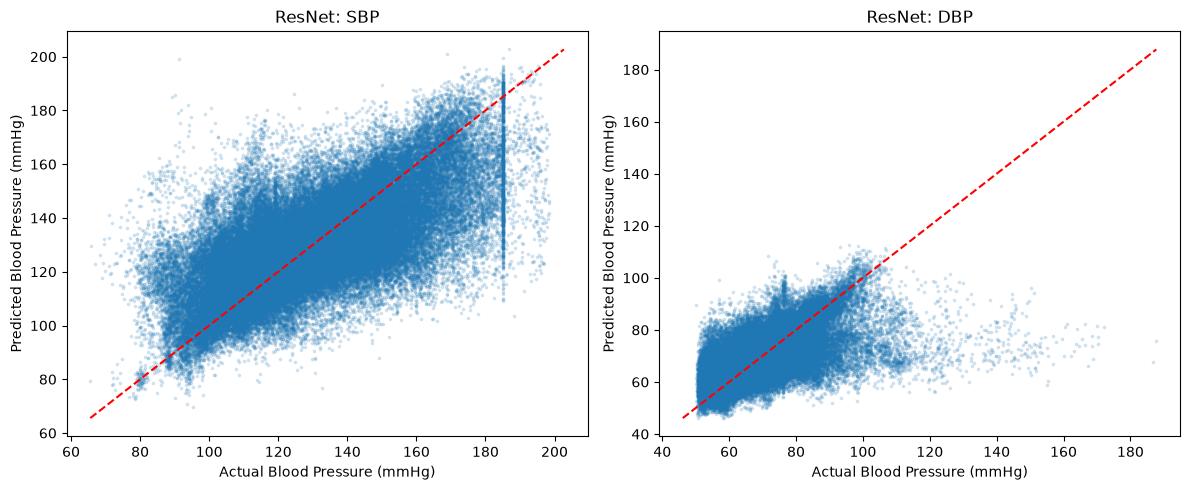

In [45]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for i, target in enumerate(["SBP", "DBP"]):

    actual = y_val_nn[:, i]
    predicted = predicted_bp[:, i]

    axes[i].scatter(
        actual,
        predicted,
        alpha=0.15,
        s=3
    )

    limits = [
        min(actual.min(), predicted.min()),
        max(actual.max(), predicted.max())
    ]

    axes[i].plot(limits, limits, "r--")

    axes[i].set_xlabel("Actual Blood Pressure (mmHg)")
    axes[i].set_ylabel("Predicted Blood Pressure (mmHg)")
    axes[i].set_title(f"ResNet: {target}")

plt.tight_layout()
plt.show()

### Prediction Analysis and Limitations

Actual-versus-predicted scatter plots were generated to examine how closely the ResNet predictions followed the reference blood pressure values.

The red dashed diagonal represents perfect predictions, where predicted blood pressure equals actual blood pressure.

#### Systolic Blood Pressure (SBP)

- Predictions generally increased as actual SBP increased.
- ResNet captured more variation in SBP than the original XGBoost model.
- Lower SBP values were frequently overestimated.
- Higher SBP values were frequently underestimated.
- Predictions still showed substantial deviations from the perfect-prediction line.

#### Diastolic Blood Pressure (DBP)

- Predictions showed a positive relationship with actual DBP in the central range.
- The model struggled with unusually high DBP readings.
- Some high DBP observations were substantially underestimated.
- Prediction errors increased toward the extremes of the distribution.

#### Error Analysis by Blood Pressure Range

Additional validation analysis showed that ResNet performed best near the middle of the observed blood pressure distribution.

| Target | Lowest-MAE Range | MAE | Highest-MAE Range | MAE |
|---|---|---:|---|---:|
| SBP | 121.6–133.8 mmHg | 8.34 | 148.2–198.4 mmHg | 17.98 |
| DBP | 62.1–67.7 mmHg | 4.31 | 75.5–187.7 mmHg | 10.43 |

These results indicate that prediction accuracy decreases at unusually high and low blood pressure values.

### Conclusion

The 1D ResNet achieved substantially better validation performance than the original XGBoost model.

**Overall improvements:**
- Approximately **22.7% lower SBP MAE**.
- Approximately **21.0% lower DBP MAE**.
- Higher R² scores for both blood pressure targets.

Unlike XGBoost, which relied on five manually extracted features, ResNet learned directly from the complete PPG waveform.

This experiment demonstrates that richer waveform representations can improve blood pressure estimation on the current dataset.

#### Remaining Limitations

1. Prediction errors remain elevated at unusually high and low blood pressure values.
2. Recording-level splitting does not guarantee patient-level independence.
3. Reference labels extracted from ABP signals may contain artifacts.
4. The ResNet has not yet been evaluated on the untouched test dataset.
5. Clinical accuracy and reliability have not been established.

